<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-17/lab-089-rnn-quantum-state.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 089. Recurrent neural network quantum state

Lab 080 and Lab 088 wrote the wave function of a spin chain as a restricted Boltzmann machine (RBM) [1]. Any network that returns one amplitude for every spin configuration can play this role, and the RBM has two costs that a recurrent network removes. Its amplitudes are known only up to the norm, a sum over all $2^N$ configurations, and its snapshots come from a Markov chain, in which each snapshot is a small change of the previous one. A recurrent neural network (RNN) writes the probability of a configuration as a product of conditional probabilities, one spin at a time, in the way the autoregressive model of Lecture 7 forecast the next value of a time series from the values before it [2, 3]. Such a product is normalised by construction, and its snapshots are drawn site by site, independently of each other [4, 5].

The lab numbers count the notebooks of the whole course, while the slides and lecture notes refer to lectures. Lab 036 belongs to Lecture 8 (recurrent networks), Lab 080 to Lecture 15 (the RBM quantum state and its training on the energy, whose numbers Lecture 16 quotes), Lab 088 to Lecture 16 (ground state and time evolution with the RBM), and this Lab 089 to Lecture 17.

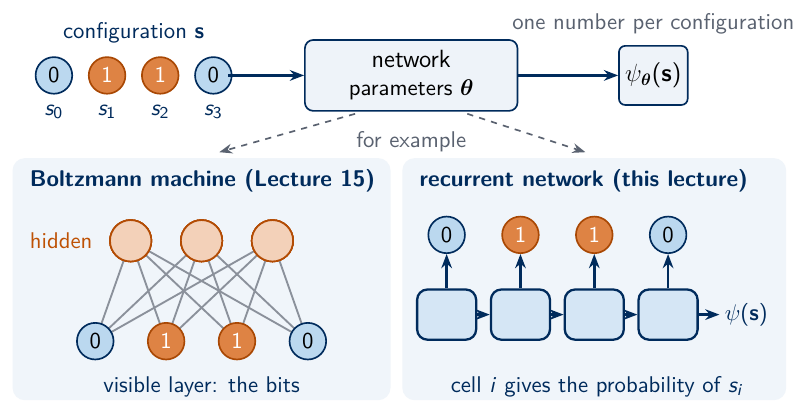

The sketch shows that any network that maps a spin configuration to an amplitude defines a wave function. The Boltzmann machine of Lecture 15 and a chain of recurrent cells are two such networks.

We use one running model, the open transverse-field Ising chain of Labs 080 and 088. Section 2 writes its two-spin ground state as a product of conditional probabilities, Section 3 builds the recurrent cell that computes these probabilities for a chain of any length, and Section 4 draws snapshots from it and checks the normalisation. The same network is then trained in three ways. Section 5 trains it on snapshots of the ground state, as the Boltzmann machines of Lecture 14 were trained on bit strings, and Section 6 compares the snapshots of the trained network with the Markov-chain snapshots of an RBM trained on the same data. Section 7 finds the ground state from the Hamiltonian alone, by lowering the energy as in Lab 080, and the work for home follows the state after a sudden change of the field, as Lab 088 did with the RBM. Chains of eight to twelve spins keep all $2^N$ amplitudes small enough to store, so exact diagonalisation checks every result.

The core route consists of Sections 1 to 7 and took 46 seconds in the recorded run, and a slower computer can need about twice as long. It ends with the line "The core route ends here." The work for home builds a conservation law into the conditional probabilities (Section 8) and follows the state in time with a step that maximises an overlap (Section 9).

## 1. Libraries

NumPy and SciPy build the Hamiltonians and diagonalise them. JAX evaluates the network for many configurations at once, computes its derivatives by automatic differentiation and compiles the training steps. The optimiser Adam [6] comes from the Optax library [7], and Matplotlib draws the figures. All calculations run in double precision on the CPU, and the GPU is never used. Parts of cells whose first comment reads "check" or "figure" test a formula or draw plots, and they may be skipped on a first reading.

The switch `SAVE_RESULTS` in the first line of the next code cell decides whether the last cell of the notebook writes files into the course folders, namely the figures, a file of LaTeX macros with the numbers quoted in the text and a results file. Its value is `False`, so running the notebook writes no file. The recorded run shown here was executed with `SAVE_RESULTS = True`, and afterwards only that line was set back to `False`.

In [1]:
SAVE_RESULTS = False      # True: the last cell writes figures/, figures/nb_numbers_lab089.tex and classroom_results/
# Imports, CPU-only JAX, figure style and two drawing helpers.
import os
os.environ["JAX_PLATFORMS"] = "cpu"                  # the GPU is never used
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
import json, time, itertools
from pathlib import Path
import numpy as np
import scipy.sparse as sparse
import scipy.sparse.linalg as sparse_linalg
from scipy.linalg import expm
import jax
import jax.numpy as jnp
import optax
from jax.flatten_util import ravel_pytree
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True)           # double precision
plt.rcParams.update({"font.size": 11, "axes.labelsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11,
                     "legend.fontsize": 11, "figure.figsize": (4.6, 3.1), "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42, "ps.fonttype": 42})
# one palette for the whole notebook: exact results black, RNN orange, RBM blue, U(1) RNN teal,
# Markov chain purple, auxiliary lines grey
COL = dict(exact="black", rnn="#D35A05", rbm="#005CA7", u1="#1B9E77", chain="#6A3D9A", grey="#9AA0A6")
FIGURES = []                                         # (name, drawing functions) of every figure, saved by the last cell

def panels(name, draws):
    # panels side by side, labelled (a), (b), ...
    fig, axes = plt.subplots(1, len(draws), figsize=(7.0, 2.9))
    for ax, draw, lab in zip(axes, draws, "abcdef"):
        draw(ax)
        ax.set_title(f"({lab})", loc="left", fontsize=11)
    fig.tight_layout(); plt.show()
    FIGURES.append((name, draws))
def one_panel(name, draw):
    fig, ax = plt.subplots(figsize=(4.6, 3.1))
    draw(ax)
    fig.tight_layout(); plt.show()
    FIGURES.append((name, [draw]))
def sci(x, digits=1):
    # a number as LaTeX scientific notation, e.g. 2.1\\times10^{-3}
    m, e = f"{x:.{digits}e}".split("e")
    return f"{m}\\times10^{{{int(e)}}}"
started = time.perf_counter()
TIMES = {}                                           # runtime of each section
NUMBERS = {}                                         # every number quoted in the text, written to the macro file at the end
print("JAX", jax.__version__, "| Optax", optax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | Optax 0.2.6 | devices: [CpuDevice(id=0)]


## 2. Two spins and the product rule

A basis state of $N$ spins is a bit string $\mathbf s=s_0s_1\dots s_{N-1}$ with $s_i\in\{0,1\}$, and site 0 is the most significant bit of the basis index $k=\sum_is_i2^{N-1-i}$. The bit 0 is the spin up, with the eigenvalue $\sigma_i=+1$ of $\hat\sigma^z_i$, and the bit 1 is the spin down, $\sigma_i=-1$, so $\sigma_i=1-2s_i$. A state is the table of amplitudes $\psi(\mathbf s)$ in $|\psi\rangle=\sum_{\mathbf s}\psi(\mathbf s)|\mathbf s\rangle$. The open transverse-field Ising chain [8],
$$\hat{\mathcal H}=-J\sum_{i=0}^{N-2}\hat\sigma^z_i\hat\sigma^z_{i+1}-g\sum_{i=0}^{N-1}\hat\sigma^x_i , \tag{1}$$
has a coupling $J$ that aligns neighbouring spins along $z$ and a transverse field $g$ that flips them. We set $J=1$ as the unit of energy. In the basis of bit strings the coupling term is diagonal, with the classical Ising energy $-J\sum_i\sigma_i\sigma_{i+1}$ of the configuration, and $\hat\sigma^x_i$ connects $\mathbf s$ with the string $\mathbf s^{(i)}$ in which bit $i$ is flipped, with the matrix element $-g$. All off-diagonal elements are negative or zero, and Lab 080 showed that the ground state then has positive amplitudes only. A measurement of all spins along $z$ gives the snapshot $\mathbf s$ with the Born probability
$$p(\mathbf s)=\frac{|\psi(\mathbf s)|^2}{Z},\qquad Z=\sum_{\mathbf s}|\psi(\mathbf s)|^2 . \tag{2}$$

For two spins at $g=J$ the ground state has the amplitudes $\psi(00)=\psi(11)=1$ and $\psi(01)=\psi(10)=r$ with $r=(\sqrt5-1)/2\approx0.618$, and the energy $-\sqrt5J$ (Lab 080). With $Z=2+2r^2$ the probabilities of the four snapshots are $p(00)=p(11)=1/(2+2r^2)\approx0.362$ and $p(01)=p(10)=r^2/(2+2r^2)\approx0.138$. The same four numbers arise when the two spins are measured one after the other. The first spin is up with the probability $p(s_0=0)=p(00)+p(01)=1/2$. Once it is known to be up, the second spin is up with the conditional probability $p(s_1=0\,|\,s_0=0)=p(00)/p(s_0=0)=1/(1+r^2)\approx0.724$, so the second spin prefers to repeat the first. Every joint probability is the product of these two factors, $p(00)=\tfrac12\times0.724=0.362$. For $N$ spins the same rule, applied site after site, gives the product rule of probability theory,
$$p(\mathbf s)=p(s_0)\,p(s_1|s_0)\,p(s_2|s_0s_1)\cdots p(s_{N-1}|s_0\dots s_{N-2})=\prod_{i=0}^{N-1}p(s_i|\mathbf s_{<i}) , \tag{3}$$
where $\mathbf s_{<i}=s_0\dots s_{i-1}$ are the spins before site $i$, and the first factor has no condition. Each conditional probability is normalised, $p(0|\mathbf s_{<i})+p(1|\mathbf s_{<i})=1$, and summing equation (3) over $s_{N-1}$, then over $s_{N-2}$ and so on down to $s_0$ gives $\sum_{\mathbf s}p(\mathbf s)=1$. A positive ground state is fixed by its probabilities, $\psi(\mathbf s)=\sqrt{p(\mathbf s)}$, so that
$$\psi(\mathbf s)=\prod_{i=0}^{N-1}\sqrt{p(s_i|\mathbf s_{<i})} . \tag{4}$$
The autoregressive model of Lecture 7 forecast the next value of a signal from the values before it. Equation (4) forecasts the next spin from the spins already fixed, and a network that returns the conditional probabilities therefore returns the amplitude. We diagonalise the two-spin Hamiltonian, compute the marginal and conditional probabilities from its ground state, rebuild the four amplitudes from equation (4) and draw the probability tree.

ground-state energy -2.2361 J,  -sqrt5 J = -2.2361 J;  r = psi(01)/psi(00) = 0.6180
snapshot   p(s)    p(s_0)   p(s_1|s_0)   sqrt(p(s_0) p(s_1|s_0))   psi(s) from diagonalisation
   00     0.362   0.500     0.724            0.6015                  0.6015
   01     0.138   0.500     0.276            0.3717                  0.3717
   10     0.138   0.500     0.276            0.3717                  0.3717
   11     0.362   0.500     0.724            0.6015                  0.6015


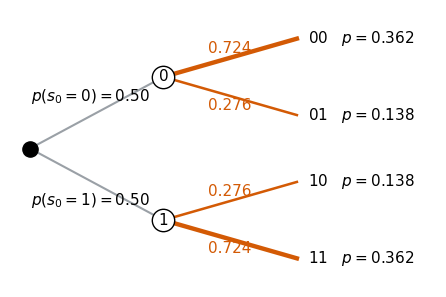

In [2]:
t_section = time.perf_counter()

def all_bits(N):
    # row k holds the bits (s_0, ..., s_{N-1}) of basis state k, site 0 is the most significant bit
    return np.array(list(itertools.product([0, 1], repeat=N)), dtype=np.int32)

def flip_table(N):
    # FLIP[k, i] = index of bit string k with bit i flipped (bit i carries the value 2^(N-1-i))
    return np.arange(2 ** N)[:, None] ^ (1 << (N - 1 - np.arange(N)))[None, :]

def tfim_matrix(N, g, J=1.0):
    # equation (1) as a sparse matrix: Ising energy on the diagonal, -g between strings one flip apart
    sigma = 1 - 2 * all_bits(N)
    diagonal = -J * np.sum(sigma[:, :-1] * sigma[:, 1:], axis=1)
    rows = np.repeat(np.arange(2 ** N), N)
    off = sparse.csr_matrix((np.full(2 ** N * N, -g), (rows, flip_table(N).ravel())), shape=(2 ** N, 2 ** N))
    return (off + sparse.diags(diagonal.astype(float))).tocsr()

# check (may be skipped): the two-spin matrix from Kronecker products of Pauli matrices, qubit 0 leftmost
I2, PX, PZ = np.eye(2), np.array([[0.0, 1.0], [1.0, 0.0]]), np.diag([1.0, -1.0])
H2 = tfim_matrix(2, 1.0).toarray()
assert np.allclose(H2, -np.kron(PZ, PZ) - (np.kron(PX, I2) + np.kron(I2, PX)))

E2, V2 = np.linalg.eigh(H2)
psi2 = V2[:, 0] * np.sign(V2[0, 0])                  # ground state, overall sign positive; order 00, 01, 10, 11
r_two = psi2[1] / psi2[0]                            # ratio r = psi(01) / psi(00)
p2 = psi2 ** 2                                       # Born probabilities (2), the vector is normalised
p_s0 = np.array([p2[0] + p2[1], p2[2] + p2[3]])      # marginal p(s_0): sum over s_1
p_cond = np.array([[p2[0], p2[1]], [p2[2], p2[3]]]) / p_s0[:, None]    # p(s_1 | s_0), row s_0, column s_1
psi_product = np.array([np.sqrt(p_s0[a] * p_cond[a, b]) for a in (0, 1) for b in (0, 1)])   # equation (4)

print(f"ground-state energy {E2[0]:.4f} J,  -sqrt5 J = {-np.sqrt(5):.4f} J;  r = psi(01)/psi(00) = {r_two:.4f}")
print("snapshot   p(s)    p(s_0)   p(s_1|s_0)   sqrt(p(s_0) p(s_1|s_0))   psi(s) from diagonalisation")
for k, lab in enumerate(["00", "01", "10", "11"]):
    a, b = k // 2, k % 2
    print(f"   {lab}     {p2[k]:.3f}   {p_s0[a]:.3f}     {p_cond[a, b]:.3f}            {psi_product[k]:.4f}                  {psi2[k]:.4f}")
assert np.allclose(psi_product, psi2)
NUMBERS.update(TwoR=f"{r_two:.3f}", TwoPAligned=f"{p2[0]:.3f}", TwoPAnti=f"{p2[1]:.3f}",
               TwoCondSame=f"{p_cond[0, 0]:.3f}", TwoCondFlip=f"{p_cond[0, 1]:.3f}", TwoEzero=f"{E2[0]:.4f}")

# --- figure (drawing code may be skipped): the probability tree ---
def draw_tree(ax):
    root, level1, level2 = (0.0, 0.0), [(1.0, 0.75), (1.0, -0.75)], [(2.0, 1.15), (2.0, 0.35), (2.0, -0.35), (2.0, -1.15)]
    for a, (x1, y1) in enumerate(level1):
        ax.plot([root[0], x1], [root[1], y1], color=COL["grey"], lw=1.5, zorder=1)
        ax.text(0.45, 0.5 * y1 + (0.17 if a == 0 else -0.17), f"$p(s_0={a})={p_s0[a]:.2f}$", ha="center", va="center", fontsize=11)
        ax.scatter([x1], [y1], s=260, color="white", edgecolor=COL["exact"], zorder=2)
        ax.text(x1, y1, f"{a}", ha="center", va="center", fontsize=11, zorder=3)
        for b in (0, 1):
            x2, y2 = level2[2 * a + b]
            lw = 1.0 + 3.0 * p_cond[a, b]
            ax.plot([x1, x2], [y1, y2], color=COL["rnn"], lw=lw, zorder=1)
            ax.text(1.5, 0.5 * (y1 + y2) + (0.1 if b == 0 else -0.1), f"{p_cond[a, b]:.3f}", ha="center", va="center", fontsize=11, color=COL["rnn"])
            ax.text(x2 + 0.08, y2, f"{a}{b}   $p={p2[2 * a + b]:.3f}$", ha="left", va="center", fontsize=11)
    ax.scatter([0], [0], s=120, color=COL["exact"], zorder=2)
    ax.set_xlim(-0.15, 3.05); ax.set_ylim(-1.45, 1.45); ax.axis("off")
one_panel("fig_lab089_tree", draw_tree)
TIMES["2 two spins"] = time.perf_counter() - t_section

The product of the marginal and the conditional probability reproduces every amplitude of the exact ground state, and the ratio $r=0.618$ appears as $\sqrt{p(01)/p(00)}$. The tree shows the two measurements one after the other. The first branching is even, because the chain has no preferred direction along $z$, and the second branching favours the branch that repeats the first spin, with the conditional probability $0.724$, drawn as the thicker line. Each leaf carries the product of the probabilities along its path.

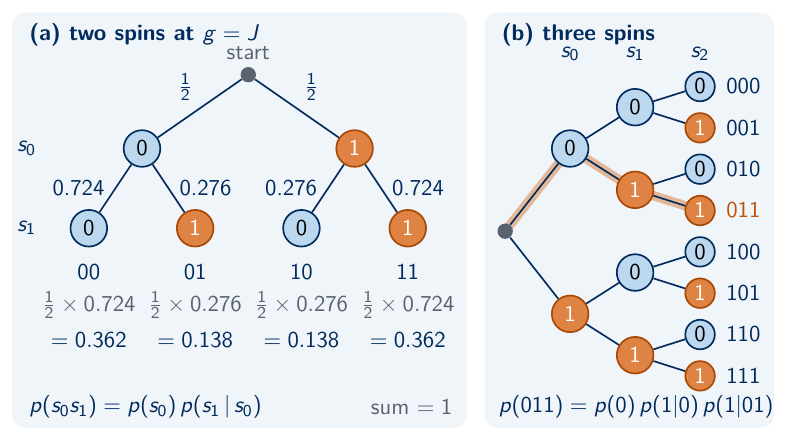

Panel (a) of the sketch repeats the two-spin tree. Panel (b), drawn schematically, follows the configuration $011$ through the tree of three spins, whose probability is the product of the three conditional probabilities along its path.

## 3. Recurrent cell

For $N$ spins the conditional probability $p(s_i|\mathbf s_{<i})$ depends on all spins before site $i$, and a table of all of them would again have $2^N$ entries. A recurrent network computes them with one rule that is applied at every site and that keeps what it has seen in a memory, the hidden vector $\mathbf h_i$ with $n_h$ real components, as the networks of Lecture 8 kept the past of a signal. At site $i$ the cell receives the previous spin as the input $\mathbf x_i$, the one-hot vector of $s_{i-1}$, which is $(1,0)$ for $s_{i-1}=0$ and $(0,1)$ for $s_{i-1}=1$, together with the previous hidden vector, and updates the memory,
$$\mathbf h_i=\tanh\big(W_h\mathbf h_{i-1}+W_x\mathbf x_i+\mathbf b\big) , \tag{5}$$
with the $n_h\times n_h$ matrix $W_h$, the $n_h\times2$ matrix $W_x$ and the bias vector $\mathbf b$, in the notation of Lab 036. The first site has no previous spin, and we start from $\mathbf h_{-1}=0$ and the zero input $\mathbf x_0=(0,0)$, so that $\mathbf h_0=\tanh\mathbf b$ is the same for every configuration. A linear readout with the $2\times n_h$ matrix $W_y$ and the vector $\mathbf b_y$ turns the memory into two numbers $z_0,z_1$, and the softmax turns these into two probabilities,
$$\big(z_0,z_1\big)=W_y\mathbf h_i+\mathbf b_y ,\qquad p(s_i=a\,|\,\mathbf s_{<i})=\frac{e^{z_a}}{e^{z_0}+e^{z_1}},\quad a\in\{0,1\} . \tag{6}$$
The two probabilities are positive and add up to one for any parameters, and $\mathbf h_i$ depends only on $s_0,\dots,s_{i-1}$, so equation (6) is a conditional probability of the kind that equation (3) needs. The spin $s_i$ then becomes the input of the next site. The same $W_h,W_x,\mathbf b,W_y,\mathbf b_y$ act at every site, so the number of parameters,
$$P=n_h^2+2n_h+n_h+2n_h+2=n_h^2+5n_h+2 , \tag{7}$$
does not depend on the length of the chain. For $n_h=16$ it is 338.

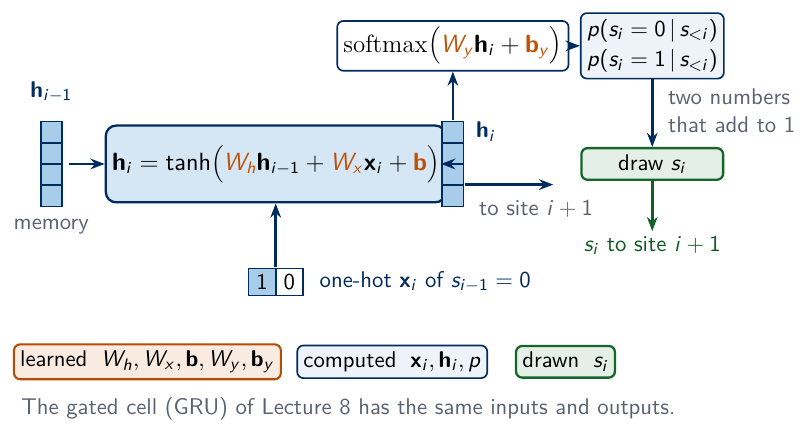

The first sketch shows one cell, which reads the memory $\mathbf h_{i-1}$ and the previous bit, updates the memory and returns the two conditional probabilities of the next bit, from which $s_i$ is drawn.

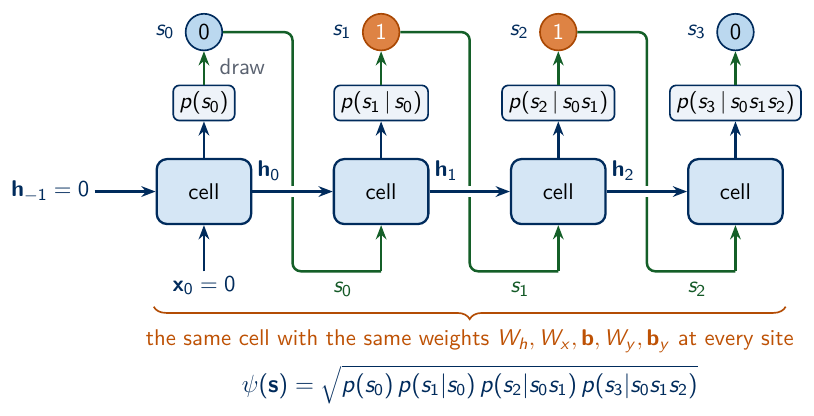

The second sketch applies the same cell at every site of a chain of four spins. Each drawn bit becomes the input of the next cell, and the square root of the product of the four conditional probabilities is the amplitude (4).

Lab 036 also introduced the gated recurrent unit (GRU) [9], whose update and reset gates decide how much of the old memory is kept. Reference [4] used it for wave functions, and it can replace equation (5) without any other change. We use the tanh cell (5), which is enough for the chains of eight to twelve spins considered here, and Exercise 6 replaces it by the GRU. For a state with complex amplitudes a second readout returns a phase $\varphi(s_i|\mathbf s_{<i})$ for each site, and the amplitude becomes $\psi(\mathbf s)=\prod_i\sqrt{p(s_i|\mathbf s_{<i})}\,e^{i\varphi(s_i|\mathbf s_{<i})}$ [4]. The ground states of Sections 5 to 7 are positive and need no phase, and Section 9 adds it for the evolution in time.

To follow one cell with numbers, a network with $n_h=2$ and parameters that we choose and round to one decimal evaluates the configuration $\mathbf s=011$ of three spins. We print the hidden vector, the two numbers $z_0,z_1$ and the conditional probabilities at every site, multiply the conditional probabilities of the spins that occur and take the square root.

In [3]:
t_section = time.perf_counter()

def rnn_hidden(params, h, x):
    # equation (5): h_i = tanh(W_h h_{i-1} + W_x x_i + b); h has shape (B, n_h), x shape (B, 2)
    return jnp.tanh(h @ params["Wh"].T + x @ params["Wx"].T + params["b"])

def rnn_conditionals(params, h):
    # equation (6): logits z = W_y h + b_y and the softmax; returns log p(0|s_<i), log p(1|s_<i), shape (B, 2)
    return jax.nn.log_softmax(h @ params["Wy"].T + params["by"])

# a cell with n_h = 2 and parameters chosen by us, rounded to one decimal
TINY = dict(Wh=jnp.array([[0.5, -0.3], [0.2, 0.4]]), Wx=jnp.array([[1.0, -1.0], [0.3, 0.8]]), b=jnp.array([0.1, -0.2]),
            Wy=jnp.array([[0.7, -0.5], [-0.6, 0.9]]), by=jnp.array([0.0, 0.1]))
s_example = [0, 1, 1]                                # the configuration 011
h = jnp.zeros((1, 2)); x = jnp.zeros((1, 2))        # h_{-1} = 0 and the zero input x_0 = (0, 0)
amplitude = 1.0
print("site  input x_i       hidden h_i            z_0, z_1         p(0|s_<i)  p(1|s_<i)   s_i   factor sqrt(p(s_i|s_<i))")
for i, s_i in enumerate(s_example):
    h = rnn_hidden(TINY, h, x)                       # new memory from the old memory and the previous spin
    z = h @ TINY["Wy"].T + TINY["by"]                  # the two numbers z_0, z_1 of equation (6)
    p = jnp.exp(rnn_conditionals(TINY, h))[0]       # softmax: the two conditional probabilities
    factor = float(jnp.sqrt(p[s_i]))
    amplitude *= factor                              # equation (4): multiply the square roots
    print(f"  {i}     ({float(x[0, 0]):.0f}, {float(x[0, 1]):.0f})     ({float(h[0, 0]):+.3f}, {float(h[0, 1]):+.3f})    "
          f"({float(z[0, 0]):+.3f}, {float(z[0, 1]):+.3f})     {float(p[0]):.3f}      {float(p[1]):.3f}      {s_i}       {factor:.4f}")
    x = jax.nn.one_hot(jnp.array([s_i]), 2)          # the spin s_i becomes the input of the next site
print(f"amplitude psi(011) = {amplitude:.4f},  probability p(011) = psi^2 = {amplitude ** 2:.4f}")
TINY_PSI011 = amplitude

site  input x_i       hidden h_i            z_0, z_1         p(0|s_<i)  p(1|s_<i)   s_i   factor sqrt(p(s_i|s_<i))
  0     (0, 0)     (+0.100, -0.197)    (+0.168, -0.137)     0.576      0.424      0       0.7589
  1     (1, 0)     (+0.836, +0.041)    (+0.565, -0.365)     0.717      0.283      1       0.5319
  2     (0, 1)     (-0.457, +0.655)    (-0.648, +0.964)     0.166      0.834      1       0.9130
amplitude psi(011) = 0.3685,  probability p(011) = psi^2 = 0.1358


The hidden vector $\mathbf h_0=\tanh\mathbf b$ of the first site is the same for every configuration, and it fixes $p(s_0)$. At site 1 the input $(1,0)$ of the spin $s_0=0$ changes the memory, and at site 2 the input $(0,1)$ of $s_1=1$ changes it again. Each row uses the same five arrays $W_h,W_x,\mathbf b,W_y,\mathbf b_y$. The amplitude is the product of the three factors in the last column.

To connect the cell with Section 2 we build a network with a single hidden unit, $n_h=1$, that returns the two-spin ground state. With $\mathbf b=0$ and $\mathbf b_y=0$ the first site gives $h_0=0$ and $p(s_0=0)=\tfrac12$. With $W_x=(1,-1)$ the hidden unit at site 1 stores the first spin as $h_1=+\tanh1$ for $s_0=0$ and $h_1=-\tanh1$ for $s_0=1$, and with $W_y=(v,-v)^{\rm T}$ the conditional probability of repeating the first spin is $1/(1+e^{-2v\tanh1})$. Setting it to $1/(1+r^2)$ gives $v=-\ln r/\tanh1\approx0.632$. We evaluate this network on the four configurations, count its parameters and compare with exact diagonalisation.

In [4]:
# a network with n_h = 1 for the two-spin ground state: b = 0, b_y = 0, W_x = (1, -1), W_y = (v, -v)^T, W_h irrelevant for two spins
v_two = -np.log(r_two) / np.tanh(1.0)
TWO = dict(Wh=jnp.zeros((1, 1)), Wx=jnp.array([[1.0, -1.0]]), b=jnp.zeros(1), Wy=jnp.array([[v_two], [-v_two]]), by=jnp.zeros(2))

def rnn_log_prob(params, s):
    # ln p(s) = sum_i ln p(s_i | s_<i), equations (3), (5), (6); s has shape (B, N) with bits 0/1
    B, N_ = s.shape
    x_prev = jnp.concatenate([jnp.zeros((B, 1, 2)), jax.nn.one_hot(s[:, :-1], 2)], axis=1)   # x_0 = (0,0), then x_i = one-hot of s_{i-1}
    def site(h, inputs):
        x, s_i = inputs
        h = rnn_hidden(params, h, x)                                       # equation (5)
        logp = rnn_conditionals(params, h)                                 # equation (6), logarithms
        return h, jnp.take_along_axis(logp, s_i[:, None], axis=1)[:, 0]    # ln p(s_i | s_<i) of the spin that occurs
    h0 = jnp.zeros((B, params["Wy"].shape[1]))
    _, logp_sites = jax.lax.scan(site, h0, (jnp.swapaxes(x_prev, 0, 1), s.T))   # loop over the sites
    return logp_sites.sum(axis=0)

psi_two_rnn = np.exp(0.5 * np.array(rnn_log_prob(TWO, jnp.array(all_bits(2)))))   # psi = sqrt(p), equation (4)
print(f"v = -ln r / tanh 1 = {v_two:.4f}")
print("psi from the one-unit network:", np.round(psi_two_rnn, 4), "  exact ground state:", np.round(psi2, 4))
assert np.allclose(psi_two_rnn, psi2)
n_params = lambda params: int(sum(np.size(a) for a in jax.tree_util.tree_leaves(params)))
print("parameters (7) for n_h = 1, 2, 16, 32:", [k * k + 5 * k + 2 for k in (1, 2, 16, 32)])
NUMBERS.update(TinyPsi=f"{TINY_PSI011:.4f}", TwoV=f"{v_two:.3f}")
TIMES["3 recurrent cell"] = time.perf_counter() - t_section

v = -ln r / tanh 1 = 0.6318
psi from the one-unit network: [0.6015 0.3717 0.3717 0.6015]   exact ground state: [0.6015 0.3717 0.3717 0.6015]
parameters (7) for n_h = 1, 2, 16, 32: [8, 16, 338, 1186]


One hidden unit reproduces the four amplitudes $(1,r,r,1)/\sqrt{2+2r^2}$ of the two-spin ground state to rounding. The unit remembers the first spin through the sign of $h_1$, and the readout turns this memory into the preference $0.724$ for a second spin parallel to the first. Longer chains need more hidden units, because the memory must carry more information about the spins already fixed.

## 4. Sampling site by site

The product rule (3) also says how to draw a snapshot. We draw $s_0$ from $p(s_0)$, feed it into the cell, draw $s_1$ from $p(s_1|s_0)$, and continue to the last site. A conditional probability has only two outcomes, so one random number $u_i$, drawn uniformly between 0 and 1, decides each spin,
$$s_i=\begin{cases}0 & \text{if } u_i<p(s_i=0\,|\,\mathbf s_{<i}),\\ 1 & \text{otherwise.}\end{cases} \tag{8}$$
The spin $s_i=0$ is drawn with the probability $p(0|\mathbf s_{<i})$, and the probability of the whole snapshot is the product (3) of the probabilities of its spins, which is $p(\mathbf s)$. Every snapshot starts from the first site with new random numbers, so two snapshots are independent of each other, and no norm $Z$ is needed. A Markov chain, as in Lab 080, moves from one snapshot to the next by small changes and needs many steps before two of its snapshots become independent.

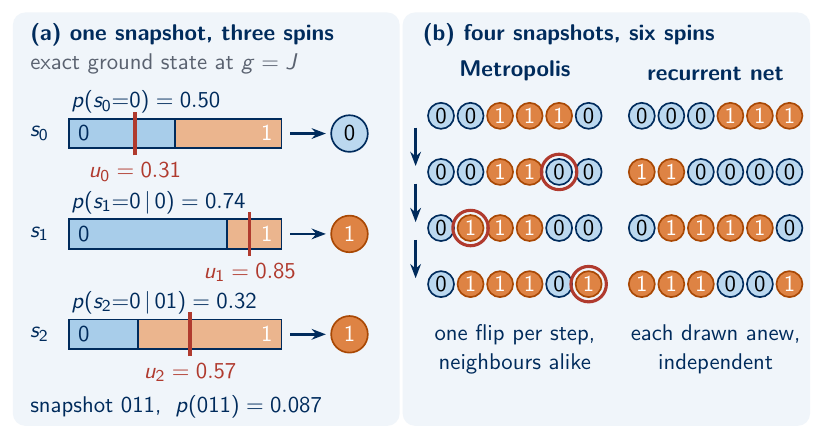

Panel (a) of the sketch draws the snapshot $011$ from the exact conditional probabilities of the three-spin ground state at $g=J$, $p(s_0=0)=0.50$, $p(s_1=0|0)=0.74$ and $p(s_2=0|01)=0.32$, with random numbers chosen for the sketch. Panel (b) sets independent snapshots beside the snapshots of a Metropolis chain, which differ by one flip from step to step (illustrative strings).

We draw one snapshot of three spins with the network of Section 3 and print, for each site, the conditional probability, the random number and the drawn spin. The slides and the lecture notes draw their table from the exact conditional probabilities of the three-spin ground state, $0.500$, $0.742$ and $0.324$, with the random numbers $0.31$, $0.85$ and $0.57$. Here the small network of Section 3 supplies the conditional probabilities and a seeded generator the random numbers, so the numbers in the table differ from those of the slides, and both tables happen to draw the snapshot $011$. The code line of equation (8) is `s_i = int(u_i >= p0)`.

In [5]:
t_section = time.perf_counter()
rng_table = np.random.default_rng(94)                # own generator for the printed table
h = jnp.zeros((1, 2)); x = jnp.zeros((1, 2))
drawn = []
print("site   p(s_i=0|s_<i)    u_i     drawn s_i")
for i in range(3):
    h = rnn_hidden(TINY, h, x)
    p0 = float(jnp.exp(rnn_conditionals(TINY, h))[0, 0])     # p(s_i = 0 | spins drawn so far)
    u_i = rng_table.random()                                 # uniform random number in [0, 1)
    s_i = int(u_i >= p0)                                     # equation (8)
    drawn.append(s_i)
    print(f"  {i}        {p0:.3f}        {u_i:.3f}       {s_i}")
    x = jax.nn.one_hot(jnp.array([s_i]), 2)                  # the drawn spin is the input of the next site
print("snapshot:", "".join(map(str, drawn)))
TABLE_SNAPSHOT = "".join(map(str, drawn))

def rnn_sample(params, key, n_samples, N_):
    # equation (8) for n_samples snapshots at once, site after site; returns bits of shape (n_samples, N_)
    def site(carry, k):
        h, x = carry
        h = rnn_hidden(params, h, x)
        p0 = jnp.exp(rnn_conditionals(params, h))[:, 0]
        s_i = (jax.random.uniform(k, (n_samples,)) >= p0).astype(jnp.int32)
        return (h, jax.nn.one_hot(s_i, 2)), s_i
    carry = (jnp.zeros((n_samples, params["Wy"].shape[1])), jnp.zeros((n_samples, 2)))
    _, s = jax.lax.scan(site, carry, jax.random.split(key, N_))
    return s.T

# check: frequencies of 100000 snapshots of the tiny network against its eight probabilities
B3 = all_bits(3)
p_tiny = np.exp(np.array(rnn_log_prob(TINY, jnp.array(B3))))
snaps = np.array(rnn_sample(TINY, jax.random.PRNGKey(0), 100_000, 3))
freq = np.bincount(snaps @ np.array([4, 2, 1]), minlength=8) / len(snaps)
print("configuration   p(s)    frequency")
for k in range(8):
    print(f"     {''.join(map(str, B3[k]))}       {p_tiny[k]:.4f}   {freq[k]:.4f}")
print(f"sum of the eight probabilities: {p_tiny.sum():.15f}")

site   p(s_i=0|s_<i)    u_i     drawn s_i
  0        0.576        0.240       0
  1        0.717        0.789       1
  2        0.166        0.722       1
snapshot: 011
configuration   p(s)    frequency
     000       0.2751   0.2720
     001       0.1378   0.1377
     010       0.0271   0.0264
     011       0.1358   0.1369
     100       0.0408   0.0422
     101       0.0277   0.0277
     110       0.0402   0.0402
     111       0.3154   0.3169
sum of the eight probabilities: 1.000000000000000


The first random number lies below the conditional probability of spin up, and the first spin is drawn up. The second and the third random number lie above it, so these spins are drawn down, and the snapshot is $011$, the configuration whose amplitude Section 3 computed. The frequencies of the 100 000 snapshots agree with the eight probabilities of the network within the statistical scatter of about $10^{-3}$, and the eight probabilities sum to one. This normalisation holds for any parameters and any length, because each softmax is normalised. We check it for a random network with $n_h=16$ on $N=10$ spins by summing all 1024 probabilities, and we draw ten snapshots of the same network.

In [6]:
def rnn_init(key, n_h, phase=False):
    # random initial parameters: W_h with standard deviation 1/sqrt(n_h), W_x with 1/sqrt(2), small readout W_y, zero biases
    k = jax.random.split(key, 4)
    params = dict(Wh=jax.random.normal(k[0], (n_h, n_h)) / np.sqrt(n_h), Wx=jax.random.normal(k[1], (n_h, 2)) / np.sqrt(2),
                  b=jnp.zeros(n_h), Wy=0.1 * jax.random.normal(k[2], (2, n_h)) / np.sqrt(n_h), by=jnp.zeros(2))
    if phase:                                        # second readout for the phase (Section 9)
        params.update(Wphi=jax.random.normal(k[3], (2, n_h)) / np.sqrt(n_h), bphi=jnp.zeros(2))
    return params

random_net = rnn_init(jax.random.PRNGKey(7), 16)
random_net = {**random_net, "Wy": 2.0 * jax.random.normal(jax.random.PRNGKey(8), (2, 16)) / 4}    # a readout of order one
BITS10 = jnp.array(all_bits(10))
p_random = np.exp(np.array(rnn_log_prob(random_net, BITS10)))
norm_dev = abs(p_random.sum() - 1)
print(f"N = 10, n_h = 16, {n_params(random_net)} parameters: sum of 1024 probabilities = {p_random.sum():.15f}, |sum - 1| = {norm_dev:.1e}")
print(f"largest and smallest probability: {p_random.max():.3e}, {p_random.min():.3e}")
print("ten snapshots:", ["".join(map(str, s)) for s in np.array(rnn_sample(random_net, jax.random.PRNGKey(1), 10, 10))])
assert norm_dev < 1e-12
NUMBERS.update(TableSnapshot=TABLE_SNAPSHOT, NormDev=f"{norm_dev:.0e}")
TIMES["4 sampling"] = time.perf_counter() - t_section

N = 10, n_h = 16, 338 parameters: sum of 1024 probabilities = 1.000000000000000, |sum - 1| = 0.0e+00
largest and smallest probability: 1.624e-02, 2.429e-06
ten snapshots: ['1111000000', '1100001100', '0110001100', '0011110000', '1000001000', '1100001001', '1110010000', '0011011000', '1100011001', '0000110001']


The 1024 probabilities of the random network sum to one to numerical precision, although no sum over configurations was ever computed when the network was built. The probabilities differ by orders of magnitude between configurations, so the normalisation is a property of the product (3) and holds for any distribution the network represents.

## 5. Learning from snapshots

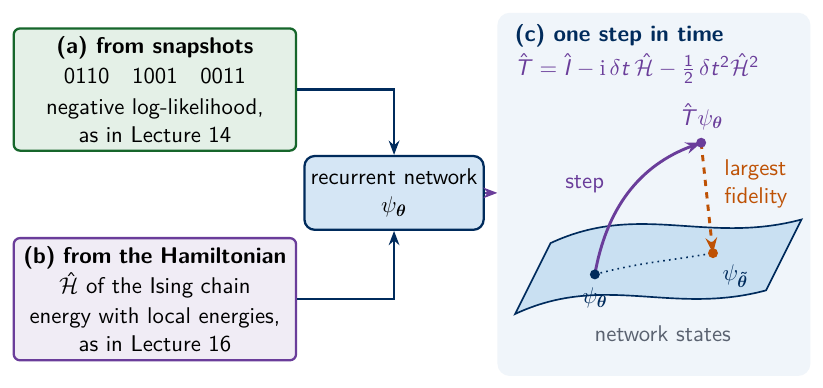

The sketch shows the three ways in which we train one network, from measured snapshots with the negative log-likelihood in this section, from the Hamiltonian with the energy in Section 7, and in time with a step whose result is brought back onto the states of the network in Section 9.

A quantum simulator that prepares the ground state of a chain and measures all spins along $z$ returns $N_{\rm data}$ snapshots $\mathbf s^{(1)},\dots,\mathbf s^{(N_{\rm data})}$, each drawn with the Born probability (2). Reconstructing the state from such a list is called quantum state tomography, and for a positive state the snapshots in the $z$ basis are enough, because the amplitudes are the square roots of the probabilities [10, 11]. We play the role of the simulator with the chain of $N=10$ spins at $g=J$. Exact diagonalisation gives its ground state $\psi_0$ and energy $\mathcal E_0$, and we draw $N_{\rm data}=20\,000$ snapshots from the table of the 1024 probabilities $\psi_0(\mathbf s)^2$.

The network is trained as the Boltzmann machines of Lecture 14 were, by minimising the negative log-likelihood of the data,
$$\mathcal L(\boldsymbol\theta)=-\frac1{N_{\rm data}}\sum_{d=1}^{N_{\rm data}}\ln p_{\boldsymbol\theta}\big(\mathbf s^{(d)}\big) , \tag{9}$$
where $\boldsymbol\theta$ collects all parameters. For the recurrent network equation (3) turns the logarithm into a sum over sites, $\ln p_{\boldsymbol\theta}(\mathbf s)=\sum_i\ln p_{\boldsymbol\theta}(s_i|\mathbf s_{<i})$, and since every factor is normalised, the loss contains no partition function. Each factor is still a softmax over the two values of one spin, so its logarithm $z_{s_i}-\ln\big(e^{z_0}+e^{z_1}\big)$ contains a normalisation, but this sum has two terms and is computed exactly at every site. The network replaces one sum over $2^N$ configurations by $N$ sums over two values. Its gradient is the derivative of these sums, which JAX computes by backpropagation through the sites, as for the recurrent networks of Lab 036.

For comparison we train an RBM on the same snapshots. We read the RBM amplitude of Lab 080 as an unnormalised probability $\tilde p_{\boldsymbol\theta}$, as Lecture 14 read the Boltzmann weight summed over the hidden units,
$$p_{\boldsymbol\theta}(\mathbf s)=\frac{\tilde p_{\boldsymbol\theta}(\mathbf s)}{Z_{\boldsymbol\theta}},\qquad \tilde p_{\boldsymbol\theta}(\mathbf s)=\exp\Big(\sum_ia_i\sigma_i\Big)\prod_{j=1}^M2\cosh\Big(b_j+\sum_iW_{ij}\sigma_i\Big),\qquad Z_{\boldsymbol\theta}=\sum_{\mathbf s}\tilde p_{\boldsymbol\theta}(\mathbf s) , \tag{10}$$
with $M$ hidden units, and take $\psi_{\boldsymbol\theta}=\sqrt{p_{\boldsymbol\theta}}=\sqrt{\tilde p_{\boldsymbol\theta}/Z_{\boldsymbol\theta}}$ as its wave function. In Labs 080 and 088 the same expression was the amplitude $\psi$ itself, so here a given set of parameters describes a different state, whose amplitudes are the square roots of the values of $\tilde p_{\boldsymbol\theta}$. The derivative of $\ln Z_{\boldsymbol\theta}$ is an average over the model distribution, and the gradient of the loss becomes the difference of two averages,
$$\frac{\partial\mathcal L}{\partial\theta_k}=-\big\langle \tilde O_k\big\rangle_{\rm data}+\big\langle \tilde O_k\big\rangle_{p_{\boldsymbol\theta}},\qquad \tilde O_k(\mathbf s)=\frac{\partial\ln\tilde p_{\boldsymbol\theta}(\mathbf s)}{\partial\theta_k} , \tag{11}$$
with $\tilde O_{a_i}=\sigma_i$, $\tilde O_{b_j}=\tanh\eta_j$ and $\tilde O_{W_{ij}}=\sigma_i\tanh\eta_j$ (the function `rbm_O` in the code), where $\eta_j=b_j+\sum_iW_{ij}\sigma_i$ is the input of hidden unit $j$. The first average runs over the snapshots, and the second over all configurations weighted with the model probabilities, which Lecture 14 estimated with Markov chains. The tilde marks the derivative of $\ln\tilde p$. From Section 7 on, $O_k=\partial\ln\psi_{\boldsymbol\theta}/\partial\theta_k$ always denotes the derivative of the logarithm of the amplitude, as in Lab 088, and for this RBM $\psi=\sqrt{\tilde p/Z}$ gives $\tilde O_k=2O_k+\partial_k\ln Z_{\boldsymbol\theta}$, where the last term is the same for every configuration. With ten spins we can afford the exact sum over the 1024 configurations, and we use it, so the RBM below is trained with the exact gradient (11). The recurrent network needs no second average at all.

We measure the quality of a trained network by two numbers computed from its full table of amplitudes, the infidelity $1-F$ with $F=\big(\sum_{\mathbf s}\psi_0(\mathbf s)\psi_{\boldsymbol\theta}(\mathbf s)\big)^2$ for normalised amplitudes, and the relative energy error $(\mathcal E_{\boldsymbol\theta}-\mathcal E_0)/|\mathcal E_0|$ with $\mathcal E_{\boldsymbol\theta}=\langle\psi_{\boldsymbol\theta}|\hat{\mathcal H}|\psi_{\boldsymbol\theta}\rangle$. Neither number enters the training. The recurrent network has $n_h=16$ and $P=338$ parameters, and the RBM has $M=30$ hidden units and $N+M+NM=340$ parameters. Both are trained with Adam [6] for 30 epochs, an epoch being one pass through the data in 100 batches of 200 snapshots, with a step size that falls from $10^{-2}$ to $10^{-4}$ along a cosine. As a third state we take the square roots of the frequencies of the snapshots themselves. We draw the data, check equation (11) against automatic differentiation, train both networks and record the two measures after every epoch.

N = 10, g = J: E_0 = -12.381490 J;  20000 snapshots, 885 different configurations of 1024
square roots of the frequencies: infidelity 1.78e-02, relative energy error 1.79e-02
largest difference between equation (11) and automatic differentiation: 1.1e-15
RNN (338 parameters): 6.6 s;  RBM (340 parameters): 3.1 s
 epoch    RNN: 1-F    dE/|E_0|      RBM: 1-F    dE/|E_0|
    0      5.47e-01   2.07e-01       5.27e-01   1.88e-01
    1      5.98e-03   1.47e-03       1.98e-02   5.54e-03
    2      7.59e-03   1.05e-03       9.83e-03   3.43e-03
    5      4.07e-03   9.23e-04       1.57e-02   3.15e-03
   10      3.21e-03   9.12e-04       9.82e-03   2.61e-03
   20      2.03e-03   8.09e-04       2.74e-03   9.78e-04
   30      1.79e-03   8.45e-04       1.47e-03   6.68e-04


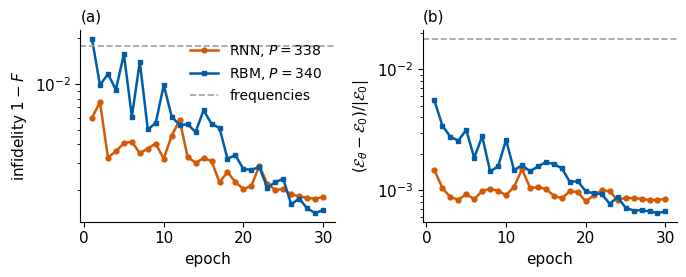

In [7]:
t_section = time.perf_counter()
N_T, G_T = 10, 1.0                                   # chain of the tomography: N = 10 at g = J
H_T = tfim_matrix(N_T, G_T)
w_T, v_T = sparse_linalg.eigsh(H_T, k=1, which="SA")
E0_T, PSI0_T = float(w_T[0]), np.abs(v_T[:, 0])      # exact ground state, all amplitudes positive
BITS_T = all_bits(N_T); SIG_T = (1 - 2 * BITS_T).astype(float)
N_DATA = 20_000
rng_data = np.random.default_rng(10)
DATA_IDX = rng_data.choice(2 ** N_T, size=N_DATA, p=PSI0_T ** 2)       # snapshots drawn with the Born probabilities
DATA = jnp.array(BITS_T[DATA_IDX])
freq_T = np.bincount(DATA_IDX, minlength=2 ** N_T) / N_DATA
print(f"N = {N_T}, g = J: E_0 = {E0_T:.6f} J;  {N_DATA} snapshots, {np.count_nonzero(freq_T)} different configurations of {2 ** N_T}")

def quality(psi):
    # infidelity 1 - F and relative energy error of the amplitudes psi (normalised here) of the N = 10 chain
    psi = psi / np.linalg.norm(psi)
    return 1 - (psi @ PSI0_T) ** 2, (psi @ (H_T @ psi) - E0_T) / abs(E0_T)
HIST_INF, HIST_DE = quality(np.sqrt(freq_T))        # the state built from the frequencies of the snapshots
print(f"square roots of the frequencies: infidelity {HIST_INF:.2e}, relative energy error {HIST_DE:.2e}")

# the RBM probability (10) and its gradient (11) with the exact model average
M_T = 30
def rbm_log_ptilde(q, sig):
    # ln p~(s) = sum_i a_i sigma_i + sum_j ln(2 cosh eta_j), eta_j = b_j + sum_i W_ij sigma_i
    eta = q["b"] + sig @ q["W"]
    return sig @ q["a"] + jnp.sum(jnp.logaddexp(eta, -eta), axis=-1)  # ln(2 cosh eta) = ln(e^eta + e^-eta)

def rbm_O(q, sig):
    # O_k(s) of equation (11): sigma_i, tanh eta_j, sigma_i tanh eta_j
    t = jnp.tanh(q["b"] + sig @ q["W"])
    return dict(a=sig, b=t, W=sig[:, :, None] * t[:, None, :])

SIG_T_J = jnp.array(SIG_T)
def rbm_gradient(q, batch_sig):
    # equation (11): minus the data average of O_k plus the exact model average over all 1024 configurations
    lp = rbm_log_ptilde(q, SIG_T_J)
    p_model = jnp.exp(lp - jax.scipy.special.logsumexp(lp))           # p(s) = p~(s) / Z
    O_data, O_all = rbm_O(q, batch_sig), rbm_O(q, SIG_T_J)
    return {k: -O_data[k].mean(axis=0) + jnp.tensordot(p_model, O_all[k], axes=1) for k in q}

def rbm_nll(q, batch_sig):
    # equation (9) for the RBM: -mean ln p~ + ln Z
    return -jnp.mean(rbm_log_ptilde(q, batch_sig)) + jax.scipy.special.logsumexp(rbm_log_ptilde(q, SIG_T_J))

# check (may be skipped): equation (11) against automatic differentiation of the loss
q_test = dict(a=0.1 * jax.random.normal(jax.random.PRNGKey(3), (N_T,)), b=0.1 * jax.random.normal(jax.random.PRNGKey(4), (M_T,)),
              W=0.1 * jax.random.normal(jax.random.PRNGKey(5), (N_T, M_T)))
g_formula, g_auto = rbm_gradient(q_test, 1.0 - 2 * DATA[:200]), jax.grad(rbm_nll)(q_test, 1.0 - 2 * DATA[:200])
grad_check_rbm = max(float(jnp.max(jnp.abs(g_formula[k] - g_auto[k]))) for k in q_test)
print(f"largest difference between equation (11) and automatic differentiation: {grad_check_rbm:.1e}")
assert grad_check_rbm < 1e-12

EPOCHS, BATCH, LR0 = 30, 200, 1e-2
STEPS_T = EPOCHS * (N_DATA // BATCH)
def make_adam():
    return optax.adam(optax.cosine_decay_schedule(LR0, STEPS_T, alpha=0.01))   # step size 1e-2 -> 1e-4

def train_on_snapshots(params, gradient_fn, amplitudes_fn, seed):
    # minibatch training on DATA; returns the parameters and the two quality measures after every epoch
    opt = make_adam(); state = opt.init(params)
    @jax.jit
    def step(params, state, batch):
        updates, state = opt.update(gradient_fn(params, batch), state, params)
        return optax.apply_updates(params, updates), state
    rng = np.random.default_rng(seed)
    history = [quality(amplitudes_fn(params))]
    for epoch in range(EPOCHS):
        order = rng.permutation(N_DATA)                                # new order of the snapshots in every epoch
        for k in range(N_DATA // BATCH):
            params, state = step(params, state, DATA[order[k * BATCH:(k + 1) * BATCH]])
        history.append(quality(amplitudes_fn(params)))
    return params, np.array(history)

BITS_T_J = jnp.array(BITS_T)
t0 = time.perf_counter()
rnn_grad = jax.grad(lambda params, batch: -jnp.mean(rnn_log_prob(params, batch)))       # equation (9), autodiff through the sites
RNN_T, HIST_RNN = train_on_snapshots(rnn_init(jax.random.PRNGKey(1), 16), rnn_grad,
                                     lambda params: np.exp(0.5 * np.array(rnn_log_prob(params, BITS_T_J))), seed=11)
SEC_RNN_T = time.perf_counter() - t0
t0 = time.perf_counter()
q0 = dict(a=jnp.zeros(N_T), b=jnp.zeros(M_T), W=0.05 * jax.random.normal(jax.random.PRNGKey(2), (N_T, M_T)))
def rbm_amplitudes(q):
    lp = np.array(rbm_log_ptilde(q, SIG_T_J)); return np.exp(0.5 * (lp - lp.max()))
RBM_T, HIST_RBM = train_on_snapshots(q0, lambda q, batch: rbm_gradient(q, 1.0 - 2 * batch), rbm_amplitudes, seed=11)
SEC_RBM_T = time.perf_counter() - t0
print(f"RNN ({n_params(RNN_T)} parameters): {SEC_RNN_T:.1f} s;  RBM ({n_params(RBM_T)} parameters): {SEC_RBM_T:.1f} s")
print(" epoch    RNN: 1-F    dE/|E_0|      RBM: 1-F    dE/|E_0|")
for e in (0, 1, 2, 5, 10, 20, 30):
    print(f"  {e:3d}      {HIST_RNN[e, 0]:.2e}   {HIST_RNN[e, 1]:.2e}       {HIST_RBM[e, 0]:.2e}   {HIST_RBM[e, 1]:.2e}")

# --- figure (drawing code may be skipped) ---
EP_AX = np.arange(EPOCHS + 1)
def draw_tomo(col):
    def draw(ax):
        ax.semilogy(EP_AX[1:], HIST_RNN[1:, col], "-o", ms=3.5, color=COL["rnn"], lw=1.8, label=f"RNN, $P={n_params(RNN_T)}$")
        ax.semilogy(EP_AX[1:], HIST_RBM[1:, col], "-s", ms=3.5, color=COL["rbm"], lw=1.8, label=f"RBM, $P={n_params(RBM_T)}$")
        ax.axhline([HIST_INF, HIST_DE][col], color=COL["grey"], ls="--", lw=1.2, label="frequencies")
        ax.set_xlabel("epoch"); ax.set_ylabel(["infidelity $1-F$", r"$(\mathcal{E}_\theta-\mathcal{E}_0)/|\mathcal{E}_0|$"][col])
        if col == 0: ax.legend(frameon=False, fontsize=10)
    return draw
panels("fig_lab089_tomography", [draw_tomo(0), draw_tomo(1)])
NUMBERS.update(TomoEzero=f"{E0_T:.4f}", TomoData=f"{N_DATA}", TomoDistinct=str(int(np.count_nonzero(freq_T))),
               HistInf=sci(HIST_INF))
TIMES["5 learning from snapshots"] = time.perf_counter() - t_section

Panel (a) shows the infidelity and panel (b) the relative energy error after every epoch, each from a single training run. After the first epoch the recurrent network is more accurate than the RBM (table below), and over 30 epochs both decrease to about $2\times10^{-3}$, where the RBM ends slightly lower. Both networks end an order of magnitude below the state built from the frequencies of the snapshots (dashed line). The 20 000 snapshots contain 885 of the 1024 configurations, many of them only a few times, so the frequencies give the rare configurations poor or zero probabilities, whereas a network with about 340 parameters assigns them probabilities that follow from the frequent ones. The two networks learn from the same snapshots, which fix the probabilities only within their statistical scatter, and Exercise 4 varies their number. The gradient of the recurrent network is a mean over the snapshots of a batch, whereas the gradient (11) of the RBM also needs the model average, which we computed here as a sum over all 1024 configurations and which for a long chain requires Markov chains, as in Lecture 14.

| single run, $N=10$, $g=J$ | RNN | RBM (exact model average) | frequencies |
|---|---|---|---|
| parameters | 338 | 340 | |
| $1-F$ after 1 epoch | $6.0\times10^{-3}$ | $2.0\times10^{-2}$ | |
| $1-F$ after 30 epochs | $1.8\times10^{-3}$ | $1.5\times10^{-3}$ | $1.8\times10^{-2}$ |
| $(\mathcal E_\theta-\mathcal E_0)/\vert\mathcal E_0\vert$ after 30 epochs | $8.4\times10^{-4}$ | $6.7\times10^{-4}$ | $1.8\times10^{-2}$ |

## 6. Markov-chain snapshots and independent snapshots

Once trained, both networks produce new snapshots, the recurrent network site by site with equation (8), each independently of all others, and the RBM with the Metropolis algorithm of Lab 080 [12]. A chain sits at a configuration $\mathbf s$, picks a random site $i$, proposes the configuration $\mathbf s^{(i)}$ with spin $i$ flipped and accepts it with the probability $\min\big(1,\tilde p(\mathbf s^{(i)})/\tilde p(\mathbf s)\big)$, in which $Z_{\boldsymbol\theta}$ cancels. A sweep consists of $N$ such proposals, and successive snapshots of one chain differ by a few flipped spins. We measure this memory with the magnetisation per spin $m(\mathbf s)=\frac1N\sum_i\sigma_i$ of each snapshot. For a sequence of snapshots $\mathbf s_1,\mathbf s_2,\dots$ its autocorrelation function at the lag $\tau$ is
$$C(\tau)=\frac{\overline{m_t\,m_{t+\tau}}-\overline{m}^{\,2}}{\overline{m^2}-\overline{m}^{\,2}} , \tag{12}$$
where $m_t=m(\mathbf s_t)$ and the bar is the average over all positions $t$ and over all sequences. $C(0)=1$, and $C(\tau)=0$ means that the snapshots $\tau$ steps apart are uncorrelated. A sum of the autocorrelation function gives the integrated autocorrelation time $\tau_{\rm int}=\frac12+\sum_{\tau\ge1}C(\tau)$, and $n$ correlated snapshots carry the statistical information of about $n/(2\tau_{\rm int})$ independent ones.

We run 200 Metropolis chains on the trained RBM of Section 5, discard 100 sweeps and record the configuration after each of the next 500 sweeps. From the trained recurrent network we draw $200\times500$ snapshots and arrange them in 200 sequences of 500. We evaluate equation (12) up to $\tau=30$ for both and compute $\tau_{\rm int}$ from these lags.

Metropolis on the RBM: acceptance 0.40;  <m^2> from the chains 0.4058, exact for the RBM 0.4067
RNN snapshots: <m^2> 0.4075, exact for the RNN 0.4074;  exact ground state 0.4115
lag tau:              1      2      3      5     10     20
C(tau), chains:    0.83   0.69   0.57   0.40   0.16   0.03
C(tau), RNN:       0.00  -0.00  -0.00   0.00   0.00   0.00
tau_int: chains 5.5 sweeps, RNN 0.49 snapshots


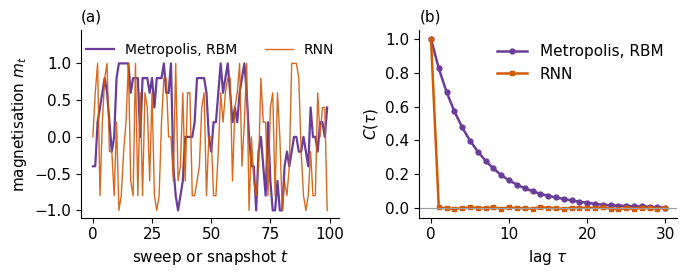

In [8]:
t_section = time.perf_counter()
CHAINS, BURN, RECORD, TAU_MAX = 200, 100, 500, 30
LOG_PT = np.array(rbm_log_ptilde(RBM_T, SIG_T_J))   # ln p~(s) of the trained RBM, looked up by the chains for speed
POW = 1 << (N_T - 1 - np.arange(N_T))                 # value 2^(N-1-i) of bit i in the basis index
rng_chain = np.random.default_rng(12)
k_state = rng_chain.integers(2 ** N_T, size=CHAINS)   # random start of every chain (basis index)
M_OF = SIG_T.mean(axis=1)                             # magnetisation m(s) of every configuration
m_chain, accepted = [], 0
for sweep in range(BURN + RECORD):
    for _ in range(N_T):                              # one sweep: N proposals per chain
        site = rng_chain.integers(N_T, size=CHAINS)
        k_new = k_state ^ POW[site]                   # flip spin `site`
        accept = np.log(rng_chain.random(CHAINS)) < LOG_PT[k_new] - LOG_PT[k_state]   # min(1, p~(s')/p~(s)), Z cancels
        k_state = np.where(accept, k_new, k_state)
        if sweep >= BURN: accepted += accept.sum()
    if sweep >= BURN:
        m_chain.append(M_OF[k_state])
M_CHAIN = np.array(m_chain).T                         # shape (chains, sweeps)
ACCEPT = accepted / (CHAINS * RECORD * N_T)
snap_rnn = np.array(rnn_sample(RNN_T, jax.random.PRNGKey(13), CHAINS * RECORD, N_T))
M_RNN = (1 - 2 * snap_rnn).mean(axis=1).reshape(CHAINS, RECORD)          # independent snapshots in 200 sequences of 500

def autocorrelation(m, tau_max):
    # equation (12), averaged over positions t and sequences
    mean, var = m.mean(), m.var()
    return np.array([1.0] + [np.mean((m[:, :-tau] - mean) * (m[:, tau:] - mean)) / var for tau in range(1, tau_max + 1)])
C_CHAIN, C_RNN = autocorrelation(M_CHAIN, TAU_MAX), autocorrelation(M_RNN, TAU_MAX)
TAU_INT_CHAIN, TAU_INT_RNN = 0.5 + C_CHAIN[1:].sum(), 0.5 + C_RNN[1:].sum()
p_rbm = np.exp(LOG_PT - LOG_PT.max()); p_rbm /= p_rbm.sum()
p_rnn = np.exp(np.array(rnn_log_prob(RNN_T, BITS_T_J)))
print(f"Metropolis on the RBM: acceptance {ACCEPT:.2f};  <m^2> from the chains {np.mean(M_CHAIN ** 2):.4f}, exact for the RBM {p_rbm @ M_OF ** 2:.4f}")
print(f"RNN snapshots: <m^2> {np.mean(M_RNN ** 2):.4f}, exact for the RNN {p_rnn @ M_OF ** 2:.4f};  exact ground state {PSI0_T ** 2 @ M_OF ** 2:.4f}")
print("lag tau:          " + "  ".join(f"{t:5d}" for t in (1, 2, 3, 5, 10, 20)))
print("C(tau), chains:   " + "  ".join(f"{C_CHAIN[t]:5.2f}" for t in (1, 2, 3, 5, 10, 20)))
print("C(tau), RNN:      " + "  ".join(f"{C_RNN[t]:5.2f}" for t in (1, 2, 3, 5, 10, 20)))
print(f"tau_int: chains {TAU_INT_CHAIN:.1f} sweeps, RNN {TAU_INT_RNN:.2f} snapshots")

# --- figure (drawing code may be skipped) ---
def draw_trace(ax):
    ax.plot(np.arange(100), M_CHAIN[0, :100], color=COL["chain"], lw=1.6, label="Metropolis, RBM")
    ax.plot(np.arange(100), M_RNN[0, :100], color=COL["rnn"], lw=1.0, alpha=0.9, label="RNN")
    ax.set_xlabel("sweep or snapshot $t$"); ax.set_ylabel("magnetisation $m_t$"); ax.set_ylim(-1.1, 1.45)
    ax.legend(frameon=False, ncol=2, loc="upper center", fontsize=10)
def draw_autocorr(ax):
    lags = np.arange(TAU_MAX + 1)
    ax.plot(lags, C_CHAIN, "-o", ms=3.5, color=COL["chain"], lw=1.8, label="Metropolis, RBM")
    ax.plot(lags, C_RNN, "-s", ms=3.5, color=COL["rnn"], lw=1.8, label="RNN")
    ax.axhline(0, color=COL["grey"], lw=0.8)
    ax.set_xlabel(r"lag $\tau$"); ax.set_ylabel(r"$C(\tau)$"); ax.legend(frameon=False)
panels("fig_lab089_autocorrelation", [draw_trace, draw_autocorr])
TIMES["6 Markov-chain and independent snapshots"] = time.perf_counter() - t_section

Panel (a) shows the magnetisation along 100 sweeps of one Metropolis chain and along 100 snapshots of the recurrent network. The chain keeps the sign of $m$ for many sweeps and changes it by a gradual drift, because a single flip changes $m$ by only $2/N$, whereas the snapshots of the network jump between positive and negative values from one snapshot to the next. Panel (b) shows the autocorrelation function (12). For the chains it falls from $0.83$ at $\tau=1$ to $0.16$ at $\tau=10$, and the integrated autocorrelation time is $\tau_{\rm int}=5.5$ sweeps, so the 500 recorded sweeps of a chain carry the information of about 45 independent snapshots. For the recurrent network $C(\tau)$ is zero within the statistical scatter at every lag, and $\tau_{\rm int}=0.49$ agrees with the value $\frac12$ of independent snapshots within the statistical scatter of about $0.02$ of the sum over 30 lags. Both sets of snapshots reproduce the mean square magnetisation $\langle m^2\rangle$ of their own network, $0.406$ from the chains against $0.407$ for the RBM and $0.407$ from the snapshots against $0.407$ for the recurrent network, and both networks lie close to $0.412$ of the exact ground state. The two trained networks therefore describe nearly the same state and differ in the cost of an independent snapshot.

## 7. Ground state from the energy

Without snapshots, the Hamiltonian alone defines the task. As in Lab 080, the energy of the network is the loss, and it is an average of the local energy over the Born probabilities,
$$\mathcal E(\boldsymbol\theta)=\sum_{\mathbf s}p_{\boldsymbol\theta}(\mathbf s)\,E_{\rm loc}(\mathbf s),\qquad E_{\rm loc}(\mathbf s)=-J\sum_{i=0}^{N-2}\sigma_i\sigma_{i+1}-g\sum_{i=0}^{N-1}\frac{\psi_{\boldsymbol\theta}(\mathbf s^{(i)})}{\psi_{\boldsymbol\theta}(\mathbf s)} , \tag{13}$$
where the ratio of amplitudes is $\sqrt{p_{\boldsymbol\theta}(\mathbf s^{(i)})/p_{\boldsymbol\theta}(\mathbf s)}$ for the positive amplitudes (4). For real parameters and a real wave function, Lab 088 derived the gradient
$$\frac{\partial\mathcal E}{\partial\theta_k}=2\big\langle\Delta O_k\,\Delta E_{\rm loc}\big\rangle,\qquad O_k(\mathbf s)=\frac{\partial\ln\psi_{\boldsymbol\theta}(\mathbf s)}{\partial\theta_k}=\frac12\frac{\partial\ln p_{\boldsymbol\theta}(\mathbf s)}{\partial\theta_k} , \tag{14}$$
where $\Delta O_k=O_k-\langle O_k\rangle$ and $\Delta E_{\rm loc}=E_{\rm loc}-\langle E_{\rm loc}\rangle$ are deviations from the averages over $p_{\boldsymbol\theta}$. The factor $\frac12$ in $O_k$ comes from $\psi=\sqrt p$, and it distinguishes $O_k$ from the derivative $\tilde O_k$ of $\ln\tilde p$ in equation (11). For the normalised recurrent network the average of $O_k$ vanishes, $\langle O_k\rangle=\frac12\sum_{\mathbf s}p_{\boldsymbol\theta}\,\partial_k\ln p_{\boldsymbol\theta}=\frac12\partial_k\sum_{\mathbf s}p_{\boldsymbol\theta}=0$, because the sum of the probabilities is one for all parameters. The subtraction of $\langle E_{\rm loc}\rangle$ then changes the exact average (14) by $\langle O_k\rangle\langle E_{\rm loc}\rangle=0$, and over a finite set of snapshots it removes most of the scatter.

Each iteration draws $n_s=500$ independent snapshots from the network with equation (8), computes their local energies from $N+1$ evaluations of the network per snapshot, and replaces the averages in equation (14) by means over the snapshots. The code obtains the gradient by automatic differentiation of the function $\frac1{n_s}\sum_{\mathbf s}\big(E_{\rm loc}(\mathbf s)-\bar E\big)\ln p_{\boldsymbol\theta}(\mathbf s)$, in which the local energies and their mean $\bar E$ are held fixed. Its derivative is $\frac1{n_s}\sum_{\mathbf s}\Delta E_{\rm loc}(\mathbf s)\,2O_k(\mathbf s)$, the snapshot form of equation (14). We take the chain of Lab 080, $N=12$ at $g=J$, check equation (14) with exact sums against the derivative of the energy, and train a network with $n_h=16$ for 2000 iterations with Adam and a step size falling from $10^{-2}$ to $10^{-4}$. Every 50 iterations we also compute the exact energy and fidelity of the network from all 4096 amplitudes.

energy (13) as average of E_loc -14.436502, from the matrix -14.436502
largest difference between equation (14) and automatic differentiation: 3.2e-15;  largest |<O_k>|: 9.1e-16
N = 12, g = J: E_0 = -14.925971 J;  training took 22.9 s
 iteration   estimate E    variance of E_loc    exact-sum energy   (E - E_0)/|E_0|   1 - F
       0      -12.06418       1.12e+01           -12.01976        1.95e-01      6.15e-01
     100      -14.91105       3.18e-02           -14.91496        7.38e-04      5.46e-03
     200      -14.92787       3.72e-02           -14.91540        7.08e-04      4.22e-03
     500      -14.92838       8.06e-03           -14.92437        1.08e-04      5.29e-04
    1000      -14.92367       1.53e-03           -14.92567        2.04e-05      7.68e-05
    1500      -14.92665       9.78e-04           -14.92580        1.14e-05      3.73e-05
    2000      -14.92562*       8.66e-04*           -14.92583        9.72e-06      3.07e-05
* mean over the last 50 iterations
core route: 46

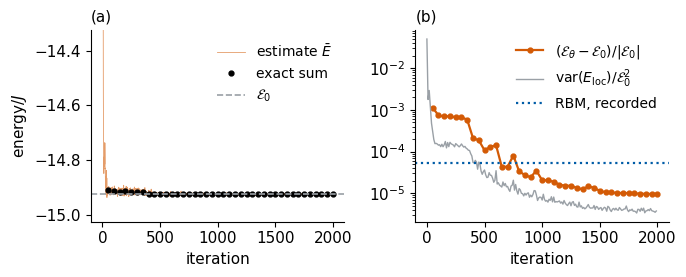

In [9]:
t_section = time.perf_counter()
N_E, G_E = 12, 1.0
H_E = tfim_matrix(N_E, G_E)
w_E, v_E = sparse_linalg.eigsh(H_E, k=1, which="SA")
E0_E, PSI0_E = float(w_E[0]), np.abs(v_E[:, 0])
BITS_E = jnp.array(all_bits(N_E))
FLIP_ONEHOT = jnp.eye(N_E, dtype=jnp.int32)

def local_energy(params, s, g=G_E, J=1.0):
    # equation (13): E_loc(s) = -J sum sigma_i sigma_{i+1} - g sum_i sqrt(p(s^(i)) / p(s)), for snapshots s of shape (B, N)
    B, N_ = s.shape
    sigma = 1 - 2 * s
    diagonal = -J * jnp.sum(sigma[:, :-1] * sigma[:, 1:], axis=1)
    flipped = (s[:, None, :] ^ FLIP_ONEHOT[None, :N_, :N_]).reshape(B * N_, N_)    # the N configurations s^(i) of every snapshot
    log_p, log_p_flip = rnn_log_prob(params, s), rnn_log_prob(params, flipped).reshape(B, N_)
    return diagonal - g * jnp.exp(0.5 * (log_p_flip - log_p[:, None])).sum(axis=1)

def energy_surrogate(params, s, e_loc):
    # derivative = (1/n_s) sum (E_loc - mean) d ln p = 2 <dO dE_loc> over the snapshots, equation (14)
    return jnp.mean(jax.lax.stop_gradient(e_loc - e_loc.mean()) * rnn_log_prob(params, s))

# check (may be skipped): equation (14) with exact sums against automatic differentiation of the exact energy (13)
net_test = {**rnn_init(jax.random.PRNGKey(20), 16), "Wy": 0.5 * jax.random.normal(jax.random.PRNGKey(21), (2, 16))}
def exact_energy(params):
    psi = jnp.exp(0.5 * rnn_log_prob(params, BITS_E))
    return psi @ (jnp.array(H_E.toarray()) @ psi)
p_all = jnp.exp(rnn_log_prob(net_test, BITS_E))
e_all = local_energy(net_test, BITS_E)
O_all = jax.vmap(jax.grad(lambda prm, s: 0.5 * rnn_log_prob(prm, s[None])[0]), in_axes=(None, 0))(net_test, BITS_E)   # O_k(s), 4096 configurations
grad_formula = {k: 2 * jnp.tensordot(p_all * (e_all - p_all @ e_all), O_all[k] - jnp.tensordot(p_all, O_all[k], axes=1), axes=1) for k in net_test}
grad_auto = jax.grad(exact_energy)(net_test)
grad_check_E = max(float(jnp.max(jnp.abs(grad_formula[k] - grad_auto[k]))) for k in net_test)
mean_O = max(float(jnp.max(jnp.abs(jnp.tensordot(p_all, O_all[k], axes=1)))) for k in net_test)
print(f"energy (13) as average of E_loc {float(p_all @ e_all):.6f}, from the matrix {float(exact_energy(net_test)):.6f}")
print(f"largest difference between equation (14) and automatic differentiation: {grad_check_E:.1e};  largest |<O_k>|: {mean_O:.1e}")
assert grad_check_E < 1e-10

ITERS, N_S = 2000, 500
opt_E = optax.adam(optax.cosine_decay_schedule(1e-2, ITERS, alpha=0.01))
@jax.jit
def energy_step(params, state, key):
    s = rnn_sample(params, key, N_S, N_E)            # independent snapshots, equation (8)
    e_loc = local_energy(params, s)
    grads = jax.grad(energy_surrogate)(params, s, e_loc)
    updates, state = opt_E.update(grads, state, params)
    return optax.apply_updates(params, updates), state, e_loc.mean(), e_loc.var()

t0 = time.perf_counter()
params_E = rnn_init(jax.random.PRNGKey(3), 16); state_E = opt_E.init(params_E)
key = jax.random.PRNGKey(4)
E_EST, VAR_EST, EXACT_LOG = [], [], []
for it in range(ITERS + 1):
    if it % 50 == 0:                                 # exact energy and fidelity from all 4096 amplitudes (a check only)
        psi = np.exp(0.5 * np.array(rnn_log_prob(params_E, BITS_E)))
        EXACT_LOG.append((it, psi @ (H_E @ psi), 1 - (psi @ PSI0_E) ** 2))
    if it == ITERS: break
    key, sub = jax.random.split(key)
    params_E, state_E, e_mean, e_var = energy_step(params_E, state_E, sub)
    E_EST.append(float(e_mean)); VAR_EST.append(float(e_var))
SEC_E = time.perf_counter() - t0
E_EST, VAR_EST, EXACT_LOG = np.array(E_EST), np.array(VAR_EST), np.array(EXACT_LOG)
REL_E = (EXACT_LOG[:, 1] - E0_E) / abs(E0_E)
print(f"N = {N_E}, g = J: E_0 = {E0_E:.6f} J;  training took {SEC_E:.1f} s")
print(" iteration   estimate E    variance of E_loc    exact-sum energy   (E - E_0)/|E_0|   1 - F")
for it in (0, 100, 200, 500, 1000, 1500, 2000):
    j = it // 50
    est = f"{E_EST[it]:10.5f}" if it < ITERS else f"{E_EST[-50:].mean():10.5f}*"
    var = f"{VAR_EST[it]:.2e}" if it < ITERS else f"{VAR_EST[-50:].mean():.2e}*"
    print(f"   {it:5d}     {est}       {var}          {EXACT_LOG[j, 1]:10.5f}        {REL_E[j]:.2e}      {EXACT_LOG[j, 2]:.2e}")
print("* mean over the last 50 iterations")

# recorded result of Lab 080 (Lecture 15): RBM with M = 12, variational Monte Carlo with Metropolis snapshots
LAB080 = dict(params=168, rel_err=5.3519930682772284e-05, fidelity=0.9998997140198131, chains=1000, iterations=1000)

# --- figure (drawing code may be skipped) ---
def draw_energy(ax):
    ax.plot(np.arange(ITERS), E_EST, color=COL["rnn"], lw=0.6, alpha=0.6, label=r"estimate $\bar E$")
    ax.plot(EXACT_LOG[:, 0], EXACT_LOG[:, 1], "o", ms=3.5, color=COL["exact"], label="exact sum")
    ax.axhline(E0_E, color=COL["grey"], ls="--", lw=1.2, label=r"$\mathcal{E}_0$")
    ax.set_ylim(E0_E - 0.1, E0_E + 0.6); ax.set_xlabel("iteration"); ax.set_ylabel(r"energy$/J$"); ax.legend(frameon=False, fontsize=10)
def draw_energy_err(ax):
    ax.semilogy(EXACT_LOG[1:, 0], REL_E[1:], "-o", ms=3.5, color=COL["rnn"], lw=1.6, label=r"$(\mathcal{E}_\theta-\mathcal{E}_0)/|\mathcal{E}_0|$")
    ax.semilogy(np.arange(ITERS)[::10], VAR_EST[::10] / E0_E ** 2, color=COL["grey"], lw=1.0, label=r"var$(E_{\rm loc})/\mathcal{E}_0^2$")
    ax.axhline(LAB080["rel_err"], color=COL["rbm"], ls=":", lw=1.6, label="RBM, recorded")
    ax.set_xlabel("iteration"); ax.legend(frameon=False, fontsize=10)
panels("fig_lab089_energy", [draw_energy, draw_energy_err])
TIMES["7 ground state from the energy"] = time.perf_counter() - t_section
CORE_SECONDS = time.perf_counter() - started
print(f"core route: {CORE_SECONDS:.0f} s")

Panel (a) shows the energy estimate $\bar E$ of every iteration (orange) and the exact energy of the network every 50 iterations (black), and panel (b) the relative energy error and the variance of the local energy on logarithmic axes. The energy falls to within $10^{-3}$ of $\mathcal E_0$ in about one hundred iterations. The estimates scatter around the exact energy, because each comes from 500 snapshots, and the scatter shrinks as the variance of the local energy falls, as it must near an eigenstate, where every snapshot has the same local energy (Lab 080). After 2000 iterations the relative energy error and the infidelity lie below the values that Lab 080 recorded for an RBM with $M=12$ trained on the same chain by variational Monte Carlo with Metropolis snapshots (dotted line in panel (b) and table below). Both are single runs with different budgets, and they show that the recurrent network trained with independent snapshots reaches the accuracy of the RBM on this chain.

| single run, $N=12$, $g=J$ | RNN, this notebook | RBM, recorded in Lab 080 |
|---|---|---|
| parameters | 338 | 168 |
| snapshots per iteration | 500 independent | 1000 Metropolis chains, 2 sweeps |
| iterations | 2000 | 1000 |
| $(\mathcal E_\theta-\mathcal E_0)/\vert\mathcal E_0\vert$ | $9.7\times10^{-6}$ | $5.4\times10^{-5}$ |
| $1-F$ | $3.1\times10^{-5}$ | $1.0\times10^{-4}$ |

The core route ends here.

## 8. At home. A conservation law built into the conditional probabilities

This section took 28 seconds in the recorded run. The XY chain [13] describes spins that exchange their orientation with their neighbours, and it has been realised with trapped ions, as discussed in Ref. [14]. With the spin operators $\hat S^\alpha_i=\hat\sigma^\alpha_i/2$ its Hamiltonian reads
$$\hat{\mathcal H}_{XY}=-J\sum_{i=0}^{N-2}\big(\hat S^x_i\hat S^x_{i+1}+\hat S^y_i\hat S^y_{i+1}\big)=-\frac J2\sum_{i=0}^{N-2}\big(\hat\sigma^+_i\hat\sigma^-_{i+1}+\hat\sigma^-_i\hat\sigma^+_{i+1}\big) , \tag{15}$$
where $\hat\sigma^+_i=(\hat\sigma^x_i+i\hat\sigma^y_i)/2$ raises spin $i$ and $\hat\sigma^-_i$ lowers it. Each term turns a neighbouring pair $01$ into $10$ or back, with the matrix element $-J/2$, and gives zero on $00$ and $11$. This flip-flop term moves a spin up from one site to the next, so the number $n_0$ of spins up (bits 0) never changes. The Hamiltonian commutes with $\sum_i\hat\sigma^z_i$, the matrix splits into blocks of fixed $n_0$, and the ground state of an open chain with an even $N$ lies in the block $n_0=N/2$, the sector of zero magnetisation. Its off-diagonal elements are negative or zero, so the ground state is positive, as for the Ising chain. Every snapshot of the ground state therefore has exactly $N/2$ spins up.

A recurrent network trained on such snapshots has to learn this rule from the data, and until it has learned it, some of its probability lies on configurations that never occur. The conservation law can also be built into the conditional probabilities [4, 14]. Let $n_0(\mathbf s_{<i})$ and $n_1(\mathbf s_{<i})$ count the spins up (bits 0) and down (bits 1) among the spins already drawn. Once $N/2$ spins are up, every further spin must be down, and once $N/2$ are down, every further spin must be up. With the Heaviside function $\Theta$, which is 1 for a positive argument and 0 otherwise, the network replaces its conditional probabilities by
$$\tilde p(0|\mathbf s_{<i})=\frac{p(0|\mathbf s_{<i})\,\Theta\big(\tfrac N2-n_0(\mathbf s_{<i})\big)}{\mathcal N_i},\qquad \tilde p(1|\mathbf s_{<i})=\frac{p(1|\mathbf s_{<i})\,\Theta\big(\tfrac N2-n_1(\mathbf s_{<i})\big)}{\mathcal N_i} , \tag{16}$$
where $\mathcal N_i$ is the sum of the two numerators, so that the two new probabilities again add up to one. The product (3) of the new conditional probabilities is normalised, it can still be sampled site by site, and it gives zero probability to every configuration outside the sector $n_0=N/2$. For the training snapshot $\mathbf s=1100$ of $N=4$ spins, the first two spins are down, so after site 1 the count $n_1=2=N/2$ sets $\tilde p(1|\mathbf s_{<i})=0$ and $\tilde p(0|\mathbf s_{<i})=1$ at sites 2 and 3, whatever the network outputs there. We call the network with equation (16) the U(1) RNN and the network without it the plain RNN. The name refers to the group U(1) of the rotations $e^{-i\alpha\hat S^z}$ about the $z$ axis, generated by the total spin $\hat S^z=\frac12\sum_i\hat\sigma^z_i$, which multiply every configuration by a phase and leave its number of spins up unchanged.

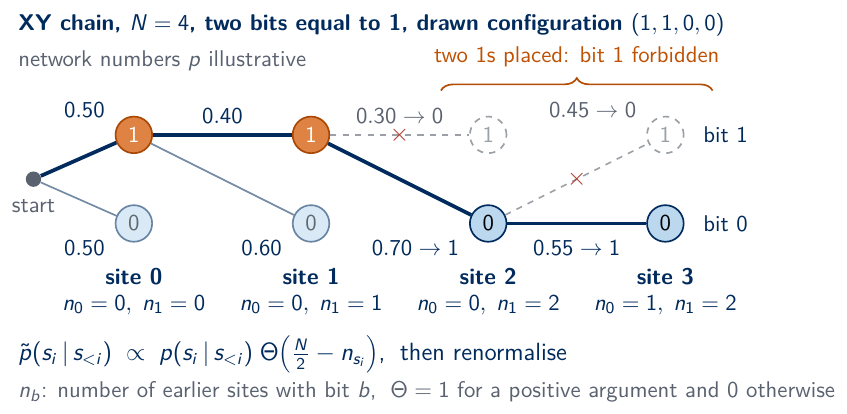

The sketch applies equation (16) to the configuration $1100$ of four spins with illustrative network probabilities. After two bits equal to 1 the branch with a third 1 is forbidden, and the conditional probabilities of the last two sites become $(1,0)$.

We implement equation (16) in the code by setting the logit of a forbidden spin to a large negative number before the softmax, print the conditional probabilities of a random network for $\mathbf s=1100$ with and without the projection, and check that the U(1) RNN on $N=10$ spins puts all of its probability into the 252 configurations of the sector.

In [10]:
t_section = time.perf_counter()

def rnn_log_prob_u1(params, s, u1=True):
    # ln p(s) with the projected conditional probabilities (16); u1=False gives the plain network of Section 3
    B, N_ = s.shape
    x_prev = jnp.concatenate([jnp.zeros((B, 1, 2)), jax.nn.one_hot(s[:, :-1], 2)], axis=1)
    def site(carry, inputs):
        h, n_up, n_down = carry
        x, s_i = inputs
        h = rnn_hidden(params, h, x)                                       # equation (5)
        z = h @ params["Wy"].T + params["by"]                                # logits of equation (6)
        if u1:
            allowed = jnp.stack([n_up < N_ // 2, n_down < N_ // 2], axis=1)   # Theta(N/2 - N_up), Theta(N/2 - N_down)
            z = jnp.where(allowed, z, -1e30)                               # forbidden spin: probability exp(-1e30) = 0
        logp = jax.nn.log_softmax(z)                                       # the softmax renormalises, N_i of equation (16)
        n_up, n_down = n_up + (s_i == 0), n_down + (s_i == 1)
        return (h, n_up, n_down), jnp.take_along_axis(logp, s_i[:, None], axis=1)[:, 0]
    zeros = jnp.zeros(B, dtype=jnp.int32)
    _, logp_sites = jax.lax.scan(site, (jnp.zeros((B, params["Wy"].shape[1])), zeros, zeros), (jnp.swapaxes(x_prev, 0, 1), s.T))
    return logp_sites.sum(axis=0)

def rnn_sample_u1(params, key, n_samples, N_, u1=True):
    # equation (8) with the projected conditional probabilities (16)
    def site(carry, k):
        h, x, n_up, n_down = carry
        h = rnn_hidden(params, h, x)
        z = h @ params["Wy"].T + params["by"]
        if u1:
            z = jnp.where(jnp.stack([n_up < N_ // 2, n_down < N_ // 2], axis=1), z, -1e30)
        s_i = (jax.random.uniform(k, (n_samples,)) >= jax.nn.softmax(z)[:, 0]).astype(jnp.int32)
        return (h, jax.nn.one_hot(s_i, 2), n_up + (s_i == 0), n_down + (s_i == 1)), s_i
    zeros = jnp.zeros(n_samples, dtype=jnp.int32)
    _, s = jax.lax.scan(site, (jnp.zeros((n_samples, params["Wy"].shape[1])), jnp.zeros((n_samples, 2)), zeros, zeros),
                        jax.random.split(key, N_))
    return s.T

# the conditional probabilities along s = 1100 for a random network with n_h = 4, plain and projected
net4 = {**rnn_init(jax.random.PRNGKey(30), 4), "Wy": jax.random.normal(jax.random.PRNGKey(31), (2, 4))}
s1100 = [1, 1, 0, 0]
h = jnp.zeros((1, 4)); x = jnp.zeros((1, 2)); n_up = n_down = 0
print("site  N_up  N_down   plain p(0), p(1)    projected p~(0), p~(1)   s_i")
for i, s_i in enumerate(s1100):
    h = rnn_hidden(net4, h, x)
    p = np.array(jnp.exp(rnn_conditionals(net4, h)))[0]
    keep = np.array([n_up < 2, n_down < 2], dtype=float)                   # Heaviside factors of equation (16), N/2 = 2
    p_proj = p * keep / np.sum(p * keep)
    print(f"  {i}    {n_up}      {n_down}       {p[0]:.3f}, {p[1]:.3f}          {p_proj[0]:.3f}, {p_proj[1]:.3f}         {s_i}")
    n_up += s_i == 0; n_down += s_i == 1
    x = jax.nn.one_hot(jnp.array([s_i]), 2)

N_XY = 10
BITS_XY = all_bits(N_XY)
N_UP = (BITS_XY == 0).sum(axis=1)                    # number of spins up of every configuration
SECTOR = N_UP == N_XY // 2
p_u1 = np.exp(np.array(rnn_log_prob_u1(random_net, jnp.array(BITS_XY))))
print(f"U(1) RNN, N = {N_XY}: sum of all probabilities {p_u1.sum():.15f}, inside the sector {p_u1[SECTOR].sum():.15f}, "
      f"{SECTOR.sum()} configurations in the sector")

site  N_up  N_down   plain p(0), p(1)    projected p~(0), p~(1)   s_i
  0    0      0       0.500, 0.500          0.500, 0.500         1
  1    0      1       0.676, 0.324          0.676, 0.324         1
  2    0      2       0.464, 0.536          1.000, 0.000         0
  3    1      2       0.500, 0.500          1.000, 0.000         0
U(1) RNN, N = 10: sum of all probabilities 1.000000000000000, inside the sector 1.000000000000000, 252 configurations in the sector


The plain network gives the spin $s_2=1$ a nonzero probability after two spins down, and the projection sets it to zero and raises the probability of $s_2=0$ to one, as in the example above. The projected network on ten spins is normalised and has no probability outside the sector.

We build the XY Hamiltonian (15) for $N=10$, find its ground state, draw 20 000 snapshots from it, and train the plain RNN and the U(1) RNN with $n_h=16$ on the same snapshots. Both use Adam with the constant step size $10^{-3}$ and batches of 50 snapshots for 20 epochs. The step size, the batch size and the number of snapshots are those of Ref. [14], whose networks were gated recurrent units with 100 hidden units trained for up to 2000 epochs. After every epoch we record the infidelity, and for the plain RNN the fraction of 2000 of its own snapshots that lie outside the sector, together with the exact probability outside the sector.

XY chain N = 10: E_0 = -3.013337 J, weight of the ground state outside the sector 5.1e-28
training time: plain 13 s, U(1) 13 s
 epoch   plain: 1-F   dE/|E_0|   outside (snapshots, exact)     U(1): 1-F   dE/|E_0|
    0      8.53e-01   2.41e-01     0.748, 0.754             6.38e-01   2.92e-01
    1      1.40e-01   1.92e-02     0.140, 0.126             9.80e-03   4.25e-03
    2      1.31e-01   1.74e-02     0.124, 0.120             7.29e-03   2.91e-03
    5      9.23e-02   1.46e-02     0.074, 0.082             5.08e-03   1.96e-03
   10      5.86e-02   1.06e-02     0.056, 0.052             5.75e-03   2.12e-03
   15      3.79e-02   6.91e-03     0.034, 0.034             3.77e-03   1.60e-03
   20      2.59e-02   5.27e-03     0.024, 0.021             3.82e-03   1.44e-03


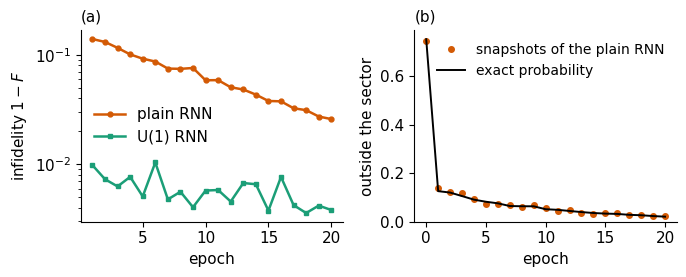

In [11]:
def xy_matrix(N_, J=1.0):
    # equation (15): -J/2 between configurations that differ by exchanging a neighbouring pair 01 <-> 10
    bits = all_bits(N_); idx = np.arange(2 ** N_); rows, cols = [], []
    for i in range(N_ - 1):
        differ = bits[:, i] != bits[:, i + 1]
        rows.append(idx[differ]); cols.append(idx[differ] ^ ((1 << (N_ - 1 - i)) | (1 << (N_ - 2 - i))))
    rows, cols = np.concatenate(rows), np.concatenate(cols)
    return sparse.csr_matrix((np.full(len(rows), -J / 2), (rows, cols)), shape=(2 ** N_, 2 ** N_))

# check (may be skipped): equation (15) from Kronecker products for N = 4
SX, SY = PX / 2, np.array([[0, -0.5j], [0.5j, 0]])
def kron_sites(ops, N_):
    out = np.ones((1, 1))
    for i in range(N_):
        out = np.kron(out, ops.get(i, I2))
    return out
H_xy4 = -sum(kron_sites({i: SX, i + 1: SX}, 4) + kron_sites({i: SY, i + 1: SY}, 4) for i in range(3))
assert np.allclose(xy_matrix(4).toarray(), H_xy4)

H_XY = xy_matrix(N_XY)
w_xy, v_xy = sparse_linalg.eigsh(H_XY, k=1, which="SA")
E0_XY, PSI0_XY = float(w_xy[0]), np.abs(v_xy[:, 0])
print(f"XY chain N = {N_XY}: E_0 = {E0_XY:.6f} J, weight of the ground state outside the sector {np.sum(PSI0_XY[~SECTOR] ** 2):.1e}")
rng_xy = np.random.default_rng(14)
DATA_XY = jnp.array(BITS_XY[rng_xy.choice(2 ** N_XY, size=20_000, p=PSI0_XY ** 2)])
BITS_XY_J = jnp.array(BITS_XY)
EPOCHS_XY, BATCH_XY = 20, 50
opt_xy = optax.adam(1e-3)

def train_xy(u1):
    params = rnn_init(jax.random.PRNGKey(1), 16); state = opt_xy.init(params)
    @jax.jit
    def step(params, state, batch):
        grads = jax.grad(lambda prm: -jnp.mean(rnn_log_prob_u1(prm, batch, u1)))(params)    # equation (9)
        updates, state = opt_xy.update(grads, state, params)
        return optax.apply_updates(params, updates), state
    rng = np.random.default_rng(15); key = jax.random.PRNGKey(16); hist = []
    def record(params, key):
        psi = np.exp(0.5 * np.array(rnn_log_prob_u1(params, BITS_XY_J, u1)))
        s = np.array(rnn_sample_u1(params, key, 2000, N_XY, u1))
        outside_samples = np.mean((s == 0).sum(axis=1) != N_XY // 2)               # fraction of snapshots outside the sector
        return (1 - (psi @ PSI0_XY) ** 2, (psi @ (H_XY @ psi) - E0_XY) / abs(E0_XY), outside_samples, np.sum(psi[~SECTOR] ** 2))
    hist.append(record(params, key))
    for epoch in range(EPOCHS_XY):
        order = rng.permutation(len(DATA_XY))
        for k in range(len(DATA_XY) // BATCH_XY):
            params, state = step(params, state, DATA_XY[order[k * BATCH_XY:(k + 1) * BATCH_XY]])
        key, sub = jax.random.split(key)
        hist.append(record(params, sub))
    return params, np.array(hist)

t0 = time.perf_counter(); _, HIST_PLAIN = train_xy(False); SEC_PLAIN = time.perf_counter() - t0
t0 = time.perf_counter(); _, HIST_U1 = train_xy(True); SEC_U1 = time.perf_counter() - t0
print(f"training time: plain {SEC_PLAIN:.0f} s, U(1) {SEC_U1:.0f} s")
print(" epoch   plain: 1-F   dE/|E_0|   outside (snapshots, exact)     U(1): 1-F   dE/|E_0|")
for e in (0, 1, 2, 5, 10, 15, 20):
    print(f"  {e:3d}      {HIST_PLAIN[e, 0]:.2e}   {HIST_PLAIN[e, 1]:.2e}     {HIST_PLAIN[e, 2]:.3f}, {HIST_PLAIN[e, 3]:.3f}             "
          f"{HIST_U1[e, 0]:.2e}   {HIST_U1[e, 1]:.2e}")

# --- figure (drawing code may be skipped) ---
EP_XY = np.arange(EPOCHS_XY + 1)
def draw_u1_inf(ax):
    ax.semilogy(EP_XY[1:], HIST_PLAIN[1:, 0], "-o", ms=3.5, color=COL["rnn"], lw=1.8, label="plain RNN")
    ax.semilogy(EP_XY[1:], HIST_U1[1:, 0], "-s", ms=3.5, color=COL["u1"], lw=1.8, label="U(1) RNN")
    ax.set_xlabel("epoch"); ax.set_ylabel("infidelity $1-F$"); ax.legend(frameon=False)
def draw_u1_out(ax):
    ax.plot(EP_XY, HIST_PLAIN[:, 2], "o", ms=4, color=COL["rnn"], label="snapshots of the plain RNN")
    ax.plot(EP_XY, HIST_PLAIN[:, 3], "-", color=COL["exact"], lw=1.4, label="exact probability")
    ax.set_xlabel("epoch"); ax.set_ylabel("outside the sector"); ax.set_ylim(bottom=0); ax.legend(frameon=False, fontsize=10)
panels("fig_lab089_u1", [draw_u1_inf, draw_u1_out])
TIMES["8 conservation law"] = time.perf_counter() - t_section

Panel (a) shows the infidelity of the two networks after every epoch, from single training runs, and panel (b) the probability that the plain RNN puts outside the sector, estimated from 2000 of its snapshots (circles) and summed exactly (line). After one epoch the plain RNN still puts $0.13$ of its probability on configurations with the wrong number of spins up. This fraction falls slowly over the 20 epochs, and the infidelity follows it down. The U(1) RNN is more accurate after its first epoch than the plain RNN after twenty (table below). The projection removes from the start the part of the task that the plain network spends its first epochs on, the rule that every snapshot has five spins up. Reference [14] observed the same faster training for longer chains and found that the plain RNN reaches a comparable accuracy after several hundred epochs.

| single run, XY chain $N=10$ | plain RNN | U(1) RNN |
|---|---|---|
| $1-F$ after 1 epoch | $0.14$ | $9.8\times10^{-3}$ |
| $1-F$ after 20 epochs | $2.6\times10^{-2}$ | $3.8\times10^{-3}$ |
| $(\mathcal E_\theta-\mathcal E_0)/\vert\mathcal E_0\vert$ after 20 epochs | $5.3\times10^{-3}$ | $1.4\times10^{-3}$ |
| probability outside the sector after 1 and 20 epochs | $0.13$, $0.02$ | 0 |

## 9. At home. Time evolution with a step that maximises an overlap

This section took 260 seconds in the recorded run, 53 seconds for the main run and 206 seconds for the scan of the time step at its end. Lab 088 followed the open chain of $N=8$ spins after a sudden change of the transverse field. The state starts in the ground state $|\psi_0\rangle$ of $\hat{\mathcal H}(g_i)$ at $g_i=0.5J$, in the ordered phase, and at $t=0$ the field jumps to $g_f=J$. The state is no eigenstate of $\hat{\mathcal H}(g_f)$ and evolves as $|\psi(t)\rangle=e^{-i\hat{\mathcal H}(g_f)t}|\psi_0\rangle$, with $\hbar=1$. We follow the transverse magnetisation per spin $\hat X=\frac1N\sum_i\hat\sigma^x_i$, whose expectation value says how far the spins point along the field, and the infidelity with the exact state, both computed from the eigenvectors of the $256\times256$ matrix of $\hat{\mathcal H}(g_f)$.

After the change of the field the amplitudes acquire phases, so the network needs the second readout of Section 3. It returns, at every site, two numbers $\varphi(0|\mathbf s_{<i})$ and $\varphi(1|\mathbf s_{<i})$ from the same hidden vector,
$$\big(\varphi(0|\mathbf s_{<i}),\varphi(1|\mathbf s_{<i})\big)=\pi\,\mathrm{softsign}\big(W_\varphi\mathbf h_i+\mathbf b_\varphi\big),\qquad \psi_{\boldsymbol\theta}(\mathbf s)=\prod_{i=0}^{N-1}\sqrt{p(s_i|\mathbf s_{<i})}\;e^{i\varphi(s_i|\mathbf s_{<i})} , \tag{17}$$
with the $2\times n_h$ matrix $W_\varphi$, the vector $\mathbf b_\varphi$ and the function softsign, which divides each component by one plus its modulus and so keeps each phase between $-\pi$ and $\pi$ [4, 5]. The phases leave $|\psi_{\boldsymbol\theta}(\mathbf s)|^2=p_{\boldsymbol\theta}(\mathbf s)$ unchanged, so the state stays normalised and can still be sampled site by site. All parameters stay real. We use $n_h=16$, with $P=372$ parameters.

Lab 088 moved the parameters of the RBM with the velocity that solves $S\dot{\boldsymbol\theta}=-if$, the velocity equation of time-dependent variational Monte Carlo (abbreviated t-VMC in the printed output below), where $f$ is the force and
$$S_{kl}=\big\langle\Delta O_k^*\,\Delta O_l\big\rangle,\qquad O_k(\mathbf s)=\frac{\partial\ln\psi_{\boldsymbol\theta}(\mathbf s)}{\partial\theta_k} , \tag{18}$$
is the covariance matrix of the logarithmic derivatives, with averages over the Born probabilities and $\Delta O_k=O_k-\langle O_k\rangle$. The parameters are real, but $O_k$ is complex, because the phase readout adds $i\sum_i\varphi(s_i|\mathbf s_{<i})$ to $\ln\psi_{\boldsymbol\theta}$, so $O_k=\frac12\partial_k\ln p_{\boldsymbol\theta}+i\,\partial_k\sum_i\varphi(s_i|\mathbf s_{<i})$. For real parameters the least-squares velocity solves the real part of this equation, $\mathrm{Re}\,S\,\dot{\boldsymbol\theta}=\mathrm{Im}\,f$. An eigenvalue $\lambda_q$ of $\mathrm{Re}\,S$ measures how much the state changes when the parameters move along the corresponding eigenvector, and directions with tiny eigenvalues need large velocities. On a $4\times4$ lattice Ref. [5] found that only a few eigenvalues are large and the rest decrease rapidly, for an autoregressive convolutional network with complex parameters and, for a gated recurrent network with real parameters, in the spectrum of the imaginary part of $S$, which that reference takes as the matrix to invert. With such spectra the inversion of an $S$ estimated from snapshots becomes unstable. We look at the spectrum of $\mathrm{Re}\,S$ for the chain of Lab 088. We fit the recurrent network, from three random starts of which we keep the best, and an RBM with $M=8$ hidden units and 80 real parameters to the exact ground state at $g_i$ by maximising the fidelity with exact sums, and compute the eigenvalues of both matrices from all 256 configurations.

The step of Ref. [5] avoids the inversion of a sampled $S$. The exact evolution over a short time $\delta t$ is $e^{-i\delta t\hat{\mathcal H}}$, and its expansion to second order,
$$\hat T=\hat 1-i\,\delta t\,\hat{\mathcal H}-\frac{\delta t^2}{2}\hat{\mathcal H}^2 , \tag{19}$$
is the propagator of the second-order Runge–Kutta method of Heun, and it differs from the exact step at third order in $\delta t$. An eigenstate with the energy $\mathcal E_n$ is multiplied by $T(\mathcal E_n)=1-i\delta t\,\mathcal E_n-(\delta t\,\mathcal E_n)^2/2$, whose squared modulus is $1+(\delta t\,\mathcal E_n)^4/4$ and whose phase is $-\delta t\,\mathcal E_n-(\delta t\,\mathcal E_n)^3/6$ to third order, against the exact phase $-\delta t\,\mathcal E_n$. Both errors grow with $|\mathcal E_n|$, change the relative weights and phases of the eigenstates, and accumulate from step to step. A constant added to $\hat{\mathcal H}$ changes only the global phase of the evolved state, and we use $\hat{\mathcal H}(g_f)-\bar{\mathcal E}$ in equation (19), with the energy $\bar{\mathcal E}=\langle\psi_0|\hat{\mathcal H}(g_f)|\psi_0\rangle$ after the change of the field, which the exact evolution conserves. The shift helps because both errors depend on the energy measured from zero. The energies themselves are of order $-9J$, whereas the shifted energies of the occupied eigenstates are spread around zero with a standard deviation of about $1.4J$, so a typical eigenstate has $\delta t\,|\mathcal E_n-\bar{\mathcal E}|\approx0.07$, against $\delta t\,|\bar{\mathcal E}|\approx0.45$ without the shift.

Given the parameters $\boldsymbol\theta$ at time $t$, the parameters $\tilde{\boldsymbol\theta}$ at time $t+\delta t$ are those whose state is closest to $\hat T|\psi_{\boldsymbol\theta}\rangle$, which means that they minimise the infidelity
$$D(\tilde{\boldsymbol\theta})=1-\frac{\big|\langle\psi_{\tilde{\boldsymbol\theta}}|\hat T|\psi_{\boldsymbol\theta}\rangle\big|^2}{\langle\psi_{\tilde{\boldsymbol\theta}}|\psi_{\tilde{\boldsymbol\theta}}\rangle\,\langle\psi_{\boldsymbol\theta}|\hat T^\dagger\hat T|\psi_{\boldsymbol\theta}\rangle} . \tag{20}$$
The overlap in the numerator is an average over the snapshots of the new network, in the way the energy was an average of the local energy,
$$\langle\psi_{\tilde{\boldsymbol\theta}}|\hat T|\psi_{\boldsymbol\theta}\rangle=\sum_{\mathbf s}|\psi_{\tilde{\boldsymbol\theta}}(\mathbf s)|^2\,T_{\rm loc}(\mathbf s),\qquad T_{\rm loc}(\mathbf s)=\sum_{\mathbf s'}\langle\mathbf s|\hat T|\mathbf s'\rangle\frac{\psi_{\boldsymbol\theta}(\mathbf s')}{\psi_{\tilde{\boldsymbol\theta}}(\mathbf s)} , \tag{21}$$
and $\hat T$ connects $\mathbf s$ only with configurations at most two flips away, because it contains $\hat{\mathcal H}^2$.

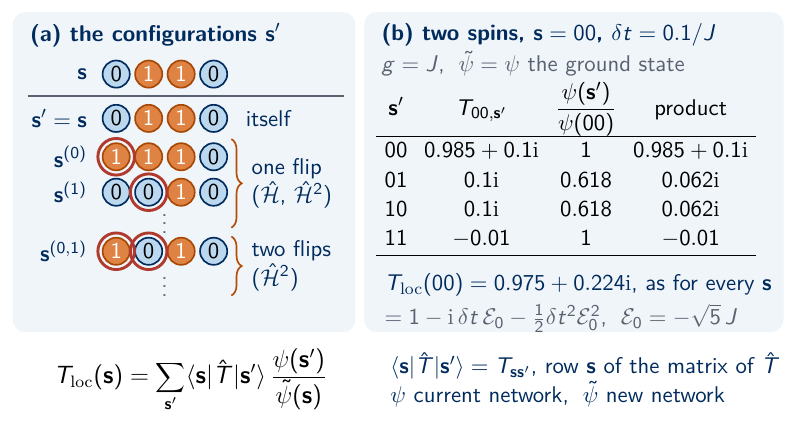

Panel (a) of the sketch shows the row of $\hat T$ for one configuration of four spins, with the configuration itself and its neighbours one and two flips away, each weighted by a ratio of amplitudes. Panel (b) evaluates $T_{\rm loc}(00)$ for the two-spin ground state at $g=J$ with $\delta t=0.1/J$ and the unshifted Hamiltonian. The state is an eigenstate, so $T_{\rm loc}$ is the same for every configuration and equals $1-i\delta t\,\mathcal E_0-\delta t^2\mathcal E_0^2/2$.

For eight spins we evaluate the overlaps as exact sums over the 256 configurations, which removes the sampling noise and leaves only the error of the network and of the optimisation. With exact sums $D$ is a smooth function of $\tilde{\boldsymbol\theta}$, and fitting one step is a least-squares problem. Its residual $|r\rangle=|\tilde\psi\rangle-|\phi\rangle\langle\phi|\tilde\psi\rangle$ is the part of the new state $|\tilde\psi\rangle=|\psi_{\tilde{\boldsymbol\theta}}\rangle$ orthogonal to the normalised target $|\phi\rangle=\hat T|\psi_{\boldsymbol\theta}\rangle/\|\hat T|\psi_{\boldsymbol\theta}\rangle\|$, and its squared length is $D$. A small real change $\delta\boldsymbol\theta$ of the parameters changes the residual by $A\,\delta\boldsymbol\theta$, where column $k$ of the matrix $A$ is the part of the vector $\tilde\psi(\mathbf s)O_k(\mathbf s)$ orthogonal to $|\phi\rangle$ (the array `A` in the code). Minimising $\|r+A\,\delta\boldsymbol\theta\|^2+\lambda\mu\|\delta\boldsymbol\theta\|^2$ over real changes gives
$$\big(\mathrm{Re}\,A^\dagger A+\lambda\mu\,I\big)\,\delta\boldsymbol\theta=-\mathrm{Re}\,A^\dagger r=-\tfrac12\nabla D ,$$
with the unit matrix $I$ and the largest diagonal element $\mu$ of $\mathrm{Re}\,A^\dagger A$, which makes $\lambda$ a pure number. Near the end of the fit the target equals the new state up to a global phase, and $(A^\dagger A)_{kl}$ becomes $\langle O_k^*O_l\rangle-\langle O_k\rangle^*\langle O_l\rangle=S_{kl}$, the matrix (18). The fit of one step is therefore the stochastic reconfiguration of Lab 088 and Lecture 16 applied to the infidelity $D$, with $\lambda\mu$ in the role of the diagonal shift. A small $\lambda$ gives the Gauss–Newton step $-(\mathrm{Re}\,S)^{-1}\nabla D/2$, which converges fast near the minimum, and a large $\lambda$ gives the short step $-\nabla D/(2\lambda\mu)$ along the negative gradient, which stays safe when $S$ is nearly singular. Each time step starts with $\lambda=10^{-3}$, divides $\lambda$ by three after a change that lowers $D$ and multiplies it by three after a rejected change. This is the Levenberg–Marquardt method [15, 16]. Our run with exact sums therefore inverts a damped $\mathrm{Re}\,S$ at every iteration, which is harmless here, because exact sums carry no statistical noise and a change that raises $D$ is rejected. Reference [5] estimated equation (21) from snapshots and minimised $D$ with Adam, which uses only the gradient and inverts no matrix. We start every step from the parameters of the previous time and use 10 iterations per step with $\delta t=0.05/J$ up to $Jt=3$, which makes 60 steps. The residual $D$ measures the distance of the new network state from $\hat T|\psi_{\boldsymbol\theta}\rangle$. The infidelity with the exact state therefore contains, besides the residuals of all steps, the truncation error of $\hat T$ itself. To measure it, we also apply $\hat T$ to the exact state vector, renormalised after every step, with no network involved, and call the result the step-operator reference.

We check equation (21) against the direct overlap, fit the ground state, compute the two spectra of $S$, and run the evolution, recording $\langle\hat X\rangle$, the infidelity with the exact state and the value of $D$ reached at every step. For the step-operator reference we evolve the exact vector with the same $\hat T$, and a second time without the energy shift. To separate the error of the steps from the limits of the network itself, we finally fit the same network directly to the exact states at $Jt=1$ and $Jt=3$.

overlap from T_loc 0.8352828713+0.2241048071j, direct 0.8352828713+0.2241048071j
infidelity of the three starts after the fit: 3.4e-02, 1.1e-05, 3.1e-04
N = 8, g_i = 0.5 J: E_0 = -7.6406 J, energy after the change of the field -8.9647 J (spread 1.43 J);  RNN with 372 parameters fitted to the ground state, infidelity 1.1e-05
RBM with M = 8 (80 real parameters) fitted to the same state, infidelity 7.6e-05
RNN: 372 eigenvalues; above 1e-3 lambda_max: 15, above 1e-6 lambda_max: 78
RBM: 80 eigenvalues; above 1e-3 lambda_max: 24, above 1e-6 lambda_max: 72
evolution: 60 steps in 16 s
  Jt     <X> exact   <X> RNN    infidelity   D after the step   step-operator reference
  0.0     0.3310     0.3310     1.06e-05       -                2.0e-15
  0.5     0.5801     0.5816     1.39e-03     1.6e-04            1.1e-04
  1.0     0.6384     0.6384     1.31e-02     1.2e-03            4.6e-04
  1.5     0.6906     0.7089     5.09e-02     2.2e-03            1.2e-03
  2.0     0.7306     0.7281     7.79e-02

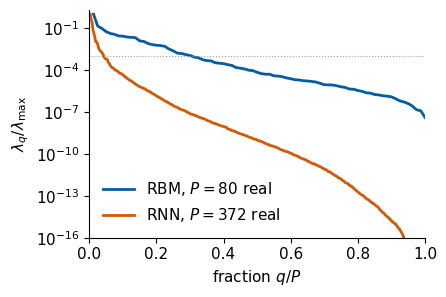

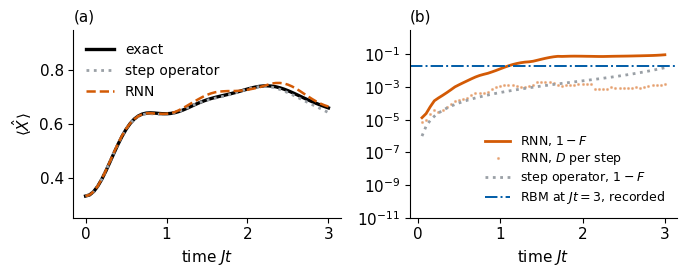

In [12]:
t_section = time.perf_counter()
N_Q, G_I, G_F = 8, 0.5, 1.0
H_I = tfim_matrix(N_Q, G_I).toarray(); H_F = tfim_matrix(N_Q, G_F).toarray()
EV_I, U_I = np.linalg.eigh(H_I); PSI0_Q = U_I[:, 0] * np.sign(U_I[0, 0])     # ground state at g_i, positive
EV_F, U_F = np.linalg.eigh(H_F); C_F = U_F.T @ PSI0_Q                        # coefficients in the eigenbasis at g_f
X_MAT = np.zeros((2 ** N_Q, 2 ** N_Q)); X_MAT[np.repeat(np.arange(2 ** N_Q), N_Q), flip_table(N_Q).ravel()] = 1.0 / N_Q
BITS_Q = jnp.array(all_bits(N_Q))
def exact_state(t):
    # |psi(t)> = sum_n e^{-i E_n t} c_n |n>, eigenstates of H(g_f)
    return U_F @ (np.exp(-1j * EV_F * t) * C_F)

def rnn_log_psi(params, s):
    # equation (17): ln psi(s) = sum_i [ (1/2) ln p(s_i|s_<i) + i phi(s_i|s_<i) ], complex, shape (B,)
    B, N_ = s.shape
    x_prev = jnp.concatenate([jnp.zeros((B, 1, 2)), jax.nn.one_hot(s[:, :-1], 2)], axis=1)
    def site(h, inputs):
        x, s_i = inputs
        h = rnn_hidden(params, h, x)                                          # equation (5)
        logp = rnn_conditionals(params, h)                                    # equation (6)
        phase = jnp.pi * jax.nn.soft_sign(h @ params["Wphi"].T + params["bphi"])   # second readout, equation (17)
        pick = lambda a: jnp.take_along_axis(a, s_i[:, None], axis=1)[:, 0]
        return h, 0.5 * pick(logp) + 1j * pick(phase)
    _, terms = jax.lax.scan(site, jnp.zeros((B, params["Wy"].shape[1])), (jnp.swapaxes(x_prev, 0, 1), s.T))
    return terms.sum(axis=0)

NET_Q = rnn_init(jax.random.PRNGKey(5), 16, phase=True)
TH_START, UNRAVEL = ravel_pytree(NET_Q)                # all parameters as one real vector theta
def amplitudes(th):
    return jnp.exp(rnn_log_psi(UNRAVEL(th), BITS_Q))  # the 256 amplitudes, normalised by construction
def infidelity_to(th, phi):
    return 1 - jnp.abs(jnp.vdot(amplitudes(th), phi)) ** 2   # D of equation (20) for a normalised target phi

def log_derivatives(th):
    # O_k(s) = d ln psi(s) / d theta_k for all 256 configurations, shape (256, P), complex
    one = lambda t, s: rnn_log_psi(UNRAVEL(t), s[None])[0]
    re = jax.vmap(jax.grad(lambda t, s: jnp.real(one(t, s))), in_axes=(None, 0))(th, BITS_Q)
    im = jax.vmap(jax.grad(lambda t, s: jnp.imag(one(t, s))), in_axes=(None, 0))(th, BITS_Q)
    return re + 1j * im

def levenberg_marquardt(th, phi, iterations, lam=1e-3):
    # minimise D = || psi - phi <phi|psi> ||^2 (equation (20) for normalised states) by damped Gauss-Newton steps
    def iteration(carry, _):
        th, lam, D = carry
        psi = amplitudes(th)
        A = psi[:, None] * log_derivatives(th)                       # d psi(s) / d theta_k
        A = A - jnp.outer(phi, phi.conj() @ A)                       # part orthogonal to the target
        r = psi - phi * (phi.conj() @ psi)                           # residual, |r|^2 = D
        G = (A.conj().T @ A).real                                    # linearised least squares for a real change
        step = jnp.linalg.solve(G + lam * jnp.max(jnp.diag(G)) * jnp.eye(len(th)), -(A.conj().T @ r).real)
        D_new = infidelity_to(th + step, phi)
        better = D_new < D                                           # accept only if D decreases
        return (jnp.where(better, th + step, th), jnp.where(better, lam / 3, lam * 3), jnp.where(better, D_new, D)), None
    (th, _, D), _ = jax.lax.scan(iteration, (th, lam, infidelity_to(th, phi)), None, length=iterations)
    return th, D

# check (may be skipped): the average of T_loc over |psi_new|^2, equation (21), equals the direct overlap
DT_Q = 0.05                                                                         # time step of the main run
E_BAR = PSI0_Q @ H_F @ PSI0_Q                                                       # energy after the change of the field
E_SPREAD = np.sqrt(C_F ** 2 @ EV_F ** 2 - (C_F ** 2 @ EV_F) ** 2)                   # standard deviation of the energy of the state
H_SHIFT = H_F - E_BAR * np.eye(2 ** N_Q)                                            # a constant shift changes only the global phase
T_MAT = np.eye(2 ** N_Q) - 1j * DT_Q * H_SHIFT - 0.5 * DT_Q ** 2 * H_SHIFT @ H_SHIFT   # equation (19)
th_a = TH_START; th_b = TH_START + 0.05 * jax.random.normal(jax.random.PRNGKey(40), TH_START.shape)
psi_a, psi_b = np.array(amplitudes(th_a)), np.array(amplitudes(th_b))
T_loc = (T_MAT @ psi_a) / psi_b                                                     # T_loc(s), equation (21)
overlap_local, overlap_direct = np.sum(np.abs(psi_b) ** 2 * T_loc), np.vdot(psi_b, T_MAT @ psi_a)
print(f"overlap from T_loc {overlap_local:.10f}, direct {overlap_direct:.10f}")
assert abs(overlap_local - overlap_direct) < 1e-12

# ground state at g_i: Adam on the infidelity, then Levenberg-Marquardt, both with exact sums
opt_fit = optax.adam(optax.cosine_decay_schedule(1e-2, 4000, alpha=0.01))
@jax.jit
def fit_step(th, state, target):
    D, g = jax.value_and_grad(infidelity_to)(th, target)
    updates, state = opt_fit.update(g, state, th)
    return optax.apply_updates(th, updates), state, D
lm_jit = jax.jit(levenberg_marquardt, static_argnums=2)
def fit_to(target, seeds=(5, 6, 7)):
    # from each of three random starts: 4000 Adam steps on the infidelity, then 30 Levenberg-Marquardt iterations;
    # returns the parameters with the lowest infidelity and the infidelities of all starts
    results = []
    for seed in seeds:
        th = ravel_pytree(rnn_init(jax.random.PRNGKey(seed), 16, phase=True))[0]
        state = opt_fit.init(th)
        for _ in range(4000):
            th, state, _ = fit_step(th, state, target)
        results.append(lm_jit(th, target, 30))
    best = min(range(len(seeds)), key=lambda j: float(results[j][1]))
    return results[best][0], results[best][1], [float(r[1]) for r in results]
TH_GS, D_GS, D_GS_STARTS = fit_to(jnp.array(PSI0_Q, dtype=complex))
print("infidelity of the three starts after the fit:", ", ".join(f"{d:.1e}" for d in D_GS_STARTS))
print(f"N = {N_Q}, g_i = {G_I} J: E_0 = {EV_I[0]:.4f} J, energy after the change of the field {E_BAR:.4f} J (spread {E_SPREAD:.2f} J);  RNN with {len(TH_START)} parameters fitted to the ground state, infidelity {float(D_GS):.1e}")

# spectra of S, equation (18), at the ground state: RNN (real part, real parameters) and RBM with M = 8 (real parameters, S real)
def covariance(O, p):
    dO = O - p @ O
    return (dO.conj().T * p) @ dO
O_rnn = np.array(log_derivatives(TH_GS)); p_gs = np.abs(np.array(amplitudes(TH_GS))) ** 2
LAM_RNN = np.sort(np.linalg.eigvalsh(covariance(O_rnn, p_gs).real))[::-1]
M_Q = 8
SIG_Q = jnp.array((1 - 2 * all_bits(N_Q)).astype(float))
def rbm_log_psi_q(q):
    a, b, W = q[:N_Q], q[N_Q:N_Q + M_Q], q[N_Q + M_Q:].reshape(N_Q, M_Q)
    eta = b + SIG_Q @ W
    return SIG_Q @ a + jnp.sum(jnp.logaddexp(eta, -eta), axis=1)                    # ln psi of the RBM (Lab 088)
def rbm_infidelity(q):
    lp = rbm_log_psi_q(q); v = jnp.exp(lp - lp.max()); v = v / jnp.linalg.norm(v)
    return 1 - (v @ PSI0_Q) ** 2
q_rbm = jnp.concatenate([jnp.zeros(N_Q + M_Q), 0.1 * jax.random.normal(jax.random.PRNGKey(1), (N_Q * M_Q,))])
opt_rbm = optax.adam(optax.cosine_decay_schedule(1e-2, 4000, alpha=0.01)); state_rbm = opt_rbm.init(q_rbm)
@jax.jit
def rbm_fit_step(q, state):
    g = jax.grad(rbm_infidelity)(q); updates, state = opt_rbm.update(g, state, q); return optax.apply_updates(q, updates), state
for _ in range(4000):
    q_rbm, state_rbm = rbm_fit_step(q_rbm, state_rbm)
O_rbm = np.array(jax.jacrev(rbm_log_psi_q)(q_rbm)).astype(complex)                  # real O_k, cast for the same covariance routine
lp_rbm = np.array(rbm_log_psi_q(q_rbm)); p_rbm_q = np.exp(2 * (lp_rbm - lp_rbm.max())); p_rbm_q /= p_rbm_q.sum()
LAM_RBM = np.sort(np.linalg.eigvalsh(covariance(O_rbm, p_rbm_q)))[::-1]
print(f"RBM with M = {M_Q} ({len(q_rbm)} real parameters) fitted to the same state, infidelity {float(rbm_infidelity(q_rbm)):.1e}")
for name, lam in (("RNN", LAM_RNN), ("RBM", LAM_RBM)):
    print(f"{name}: {len(lam)} eigenvalues; above 1e-3 lambda_max: {np.sum(lam > 1e-3 * lam[0])}, above 1e-6 lambda_max: {np.sum(lam > 1e-6 * lam[0])}")

# the evolution: Heun step (19) and minimisation of D (20) at every step
LM_ITERS_Q, T_END = 10, 3.0
T_J = jnp.array(T_MAT)
@jax.jit
def heun_step(th):
    phi = T_J @ amplitudes(th); phi = phi / jnp.linalg.norm(phi)     # normalised target T|psi_theta>
    return levenberg_marquardt(th, phi, LM_ITERS_Q)
n_steps = int(round(T_END / DT_Q))
t0 = time.perf_counter()
th = TH_GS; T_Q, X_EXACT_Q, X_RNN_Q, INF_Q, D_STEP = [], [], [], [], []
for k in range(n_steps + 1):
    t = k * DT_Q
    psi_ex, psi_net = exact_state(t), np.array(amplitudes(th))
    T_Q.append(t); X_EXACT_Q.append(np.vdot(psi_ex, X_MAT @ psi_ex).real); X_RNN_Q.append(np.vdot(psi_net, X_MAT @ psi_net).real)
    INF_Q.append(1 - abs(np.vdot(psi_net, psi_ex)) ** 2)
    if k < n_steps:
        th, D = heun_step(th); D_STEP.append(float(D))
SEC_TE = time.perf_counter() - t0
T_Q, X_EXACT_Q, X_RNN_Q, INF_Q, D_STEP = map(np.array, (T_Q, X_EXACT_Q, X_RNN_Q, INF_Q, D_STEP))
DX_MAX = np.max(np.abs(X_RNN_Q - X_EXACT_Q))

# step-operator reference: the same T applied to the exact vector, renormalised after every step, no network;
# with the shifted Hamiltonian of the evolution and, for comparison, with the unshifted one
T_UNSHIFT = np.eye(2 ** N_Q) - 1j * DT_Q * H_F - 0.5 * DT_Q ** 2 * H_F @ H_F
def step_operator_reference(T):
    psi = PSI0_Q.astype(complex); x_ref, inf_ref = [], []
    for k in range(n_steps + 1):
        psi_ex = exact_state(k * DT_Q)
        x_ref.append(np.vdot(psi, X_MAT @ psi).real); inf_ref.append(1 - abs(np.vdot(psi, psi_ex)) ** 2)
        psi = T @ psi; psi = psi / np.linalg.norm(psi)
    return np.array(x_ref), np.array(inf_ref)
X_STEP_Q, INF_STEP_Q = step_operator_reference(T_MAT)
_, INF_STEP_UNSHIFT = step_operator_reference(T_UNSHIFT)
DX_STEP_MAX = np.max(np.abs(X_STEP_Q - X_EXACT_Q))

print(f"evolution: {n_steps} steps in {SEC_TE:.0f} s")
print("  Jt     <X> exact   <X> RNN    infidelity   D after the step   step-operator reference")
for t in (0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0):
    k = int(round(t / DT_Q))
    print(f"  {t:3.1f}     {X_EXACT_Q[k]:.4f}     {X_RNN_Q[k]:.4f}     {INF_Q[k]:.2e}     " + (f"{D_STEP[k - 1]:.1e}" if k else "  -    ")
          + f"            {INF_STEP_Q[k]:.1e}")
print(f"largest |<X>_RNN - <X>_exact| = {DX_MAX:.3f};  infidelity at Jt = 3: {INF_Q[-1]:.1e};  sum of D over all steps: {D_STEP.sum():.1e}")
print(f"step-operator reference: infidelity at Jt = 3 {INF_STEP_Q[-1]:.1e} with the shift, {INF_STEP_UNSHIFT[-1]:.1e} without it; "
      f"largest |<X>_step - <X>_exact| = {DX_STEP_MAX:.1e}")
# check: direct fits of the same network to the exact states at Jt = 1 and 3, what the network can represent
DIRECT = {t_fit: float(fit_to(jnp.array(exact_state(t_fit)))[1]) for t_fit in (1.0, 3.0)}     # best of three starts
print("direct fit to the exact state: " + ",  ".join(f"Jt = {t_:.0f}: infidelity {v:.1e}" for t_, v in DIRECT.items()))
LAB088 = dict(max_abs_dx=0.010264765906534024, infid_T=0.019681255537356113,      # recorded in Lab 088, RBM M = 8, exact sums,
              integrator="fourth-order Runge-Kutta", dt=0.005)                       # velocity equation integrated with RK4, dt = 0.005/J
print(f"recorded in Lab 088 (RBM with M = 8, t-VMC with exact sums, fourth-order Runge-Kutta with dt = 0.005/J): largest deviation {LAB088['max_abs_dx']:.3f}, infidelity at Jt = 3 {LAB088['infid_T']:.1e}")

# --- figures (drawing code may be skipped) ---
def draw_qgt(ax):
    # eigenvalues against the fraction q/P of all parameter directions
    for lam, col, name in ((LAM_RBM, COL["rbm"], "RBM"), (LAM_RNN, COL["rnn"], "RNN")):
        frac = np.arange(1, len(lam) + 1) / len(lam)
        ax.semilogy(frac, np.clip(lam / lam[0], 1e-18, None), "-", color=col, lw=2, label=f"{name}, $P={len(lam)}$ real")
    ax.axhline(1e-3, color=COL["grey"], lw=0.8, ls=":")
    ax.set_ylim(1e-16, 2); ax.set_xlim(0, 1)
    ax.set_xlabel("fraction $q/P$"); ax.set_ylabel(r"$\lambda_q/\lambda_{\max}$"); ax.legend(frameon=False)
one_panel("fig_lab089_qgt_spectrum", draw_qgt)
def draw_quench_x(ax):
    ax.plot(T_Q, X_EXACT_Q, color=COL["exact"], lw=2.4, label="exact")
    ax.plot(T_Q, X_STEP_Q, ":", color=COL["grey"], lw=2.0, label="step operator")
    ax.plot(T_Q, X_RNN_Q, "--", color=COL["rnn"], lw=1.8, label="RNN")
    ax.set_ylim(0.25, 0.95); ax.set_xlabel("time $Jt$"); ax.set_ylabel(r"$\langle\hat X\rangle$")
    ax.legend(frameon=False, loc="upper left", fontsize=10)
def draw_quench_inf(ax):
    ax.semilogy(T_Q[1:], INF_Q[1:], color=COL["rnn"], lw=2, label="RNN, $1-F$")
    ax.semilogy(T_Q[1:], D_STEP, ".", ms=2.5, color=COL["rnn"], alpha=0.35, label="RNN, $D$ per step")
    ax.semilogy(T_Q[1:], INF_STEP_Q[1:], ":", color=COL["grey"], lw=2.0, label="step operator, $1-F$")
    ax.axhline(LAB088["infid_T"], color=COL["rbm"], ls="-.", lw=1.4, label="RBM at $Jt=3$, recorded")
    ax.set_ylim(1e-11, 3.0); ax.set_xlabel("time $Jt$"); ax.legend(frameon=False, fontsize=9, loc="lower right", labelspacing=0.25)
panels("fig_lab089_quench", [draw_quench_x, draw_quench_inf])
TIMES["9 time evolution, main run"] = time.perf_counter() - t_section

The first figure shows the eigenvalues $\lambda_q$ of $\mathrm{Re}\,S$ at the ground state, divided by the largest one and sorted, against the fraction $q/P$ of all parameter directions. For the RBM, 24 of its 80 eigenvalues lie within three orders of magnitude of the largest (dotted line), and for the recurrent network only 15 of its 372 eigenvalues do. The spectrum of the recurrent network falls below $10^{-6}\lambda_{\max}$ after about a fifth of its directions and reaches values that are zero in double precision, whereas that of the RBM stays above this level for most of its directions. Most directions in the parameter space of the recurrent network change the state very little. Reference [5] saw equally steep spectra on a $4\times4$ lattice, for its recurrent network with real parameters in the imaginary part of $S$, and the figure shows the same behaviour of $\mathrm{Re}\,S$ for one example on eight spins.

In the second figure, panel (a) shows $\langle\hat X\rangle(t)$ and panel (b) the infidelity with the exact state together with the value of $D$ left after each step, from a single run. The dotted grey curves belong to the step-operator reference. With $\delta t=0.05/J$ its infidelity grows to $1.5\times10^{-2}$ at $Jt=3$ and its $\langle\hat X\rangle$ deviates from the exact curve by up to $1.8\times10^{-2}$, so the truncation error of $\hat T$ is a visible part of the error at late times. Without the energy shift the same reference reaches $8.0\times10^{-2}$ at $Jt=3$.

The ground-state fit starts with the infidelity $1.1\times10^{-5}$. The network follows the fast rise of $\langle\hat X\rangle$ during the first time unit, with the infidelity $1.4\times10^{-3}$ at $Jt=0.5$ and $1.3\times10^{-2}$ at $Jt=1$, where the reference is still at $4.6\times10^{-4}$, so at early times the error comes from the residuals $D$. Beyond this time $\langle\hat X\rangle$ deviates from the exact curve by up to $0.022$, and the infidelity grows to $9.6\times10^{-2}$ at $Jt=3$. Fitted directly to the exact states, the same network reaches the infidelities $6.6\times10^{-4}$ at $Jt=1$ and $2.5\times10^{-3}$ at $Jt=3$, so it can represent these states, and the error comes from following them one step at a time. The infidelity at $Jt=3$ exceeds the sum $5.7\times10^{-2}$ of the residuals of all sixty steps together with the truncation error of the reference. For two normalised states we use the angle $\theta(a,b)=\arccos|\langle a|b\rangle|$, so that their infidelity is $\sin^2\theta$ and a residual is $D=\sin^2\theta$ of the new network state and the target of its step. The angle does not change when the same unitary acts on both states, because $\langle a|\hat U^\dagger\hat U|b\rangle=\langle a|b\rangle$. It obeys the triangle inequality $\theta(a,c)\le\theta(a,b)+\theta(b,c)$, which follows from writing $|a\rangle=\cos\alpha|b\rangle+\sin\alpha|a_\perp\rangle$ and $|c\rangle=\cos\gamma|b\rangle+\sin\gamma|c_\perp\rangle$ with $\alpha=\theta(a,b)$, $\gamma=\theta(b,c)$ and normalised $|a_\perp\rangle,|c_\perp\rangle$ orthogonal to $|b\rangle$, so that $|\langle a|c\rangle|\ge\cos\alpha\cos\gamma-\sin\alpha\sin\gamma=\cos(\alpha+\gamma)$. With the exact state $|\phi_n\rangle$ after $n$ steps, the network state $|\psi_n\rangle$ and the truncation angle $\varepsilon_n$ of $\hat T$, two triangle inequalities, through the target and through $e^{-i\delta t\hat{\mathcal H}}|\psi_{n-1}\rangle$, give $\theta(\psi_n,\phi_n)\le\arcsin\sqrt{D_n}+\varepsilon_n+\theta(\psi_{n-1},\phi_{n-1})$. The exact evolution keeps an existing deviation, each step adds an angle of about $\sqrt D$, and the final angle is at most the sum of the step angles. The infidelity, the squared sine of the final angle, can therefore exceed the sum of the residuals, and if the deviations of all $n$ steps pointed the same way, $n$ equal residuals would give an infidelity $n$ times their sum. The deviations of successive steps build up faster than the sum of the residuals, because the deviations of successive steps are partly aligned, so their angles add up instead of their squares.

The RBM of Lab 088 with $M=8$ and complex parameters followed the same change of the field with the velocity equation $S\dot{\boldsymbol\theta}=-if$, exact sums and fourth-order Runge–Kutta steps of $0.005/J$, and recorded the largest deviation $0.010$ and the infidelity $2.0\times10^{-2}$ at $Jt=3$. The two calculations differ in the network, the equation of motion and the integrator, so the table compares two complete methods. With exact sums on eight spins the velocity equation can use the full matrix $S$, and in this setting the RBM with the velocity equation stays closer to the exact state than the recurrent network with the variational step. The variational step was designed for averages from snapshots, where the inversion of a sampled $S$ with the spectrum above is the obstacle that the step avoids, and with snapshots Ref. [5] reported agreement with exact results for small two-dimensional lattices.

| single run, $N=8$, $g_i=0.5J\to g_f=J$ | RNN, variational step, this notebook | RBM $M=8$, velocity equation, recorded in Lab 088 |
|---|---|---|
| parameters | 372 real | 80 complex |
| eigenvalues of $S$ above $10^{-3}\lambda_{\max}$ | 15 of 372 ($\mathrm{Re}\,S$) | 24 of 80 (real-parameter fit in this notebook) |
| equation of motion | minimum of $D$, equation (20), at every step | $S\dot{\boldsymbol\theta}=-if$, exact sums |
| integrator and time step | Heun step $\hat T$, equation (19), $\delta t=0.05/J$, 60 steps | fourth-order Runge–Kutta, $dt=0.005/J$ |
| step-operator reference, $1-F$ at $Jt=3$ | $1.5\times10^{-2}$ | |
| $1-F$ at $Jt=1$ | $1.3\times10^{-2}$ | |
| largest $\vert\langle\hat X\rangle_\theta-\langle\hat X\rangle\vert$ up to $Jt=3$ | $0.022$ | $0.010$ |
| $1-F$ at $Jt=3$ | $9.6\times10^{-2}$ | $2.0\times10^{-2}$ |
| direct fit at $Jt=1$, $Jt=3$ | $6.6\times10^{-4}$, $2.5\times10^{-3}$ | |

### Choice of the time step

The time step enters the calculation twice. A larger $\delta t$ makes $\hat T$ a worse approximation of $e^{-i\delta t\hat{\mathcal H}}$, and the step-operator reference measures this truncation error without any network. A smaller $\delta t$ needs more steps up to the same final time, and every step leaves its own residual $D$ after the minimisation. Reference [5] observed both effects for the variational Heun step with snapshots on a $4\times4$ lattice (its Fig. 5(a)) and found "a threshold around $g\delta t = 0.01$ past which the error cannot be reduced by decreasing the time step", which it attributes to "the systematic error stemming from the optimization process", and it noted that "for a given fixed total simulation time, a larger number of time steps is required, thereby proportionally increasing the total error". That reference found its optimal step at $g\,\delta t\approx0.01$.

We ask which of the two effects our data show. We repeat the evolution of the main run, with the same network, the same ground-state fit, 10 Levenberg–Marquardt iterations per step and exact sums, for $\delta t=0.01/J$, $0.025/J$ and $0.1/J$, take the main run for $\delta t=0.05/J$, and compute the step-operator reference for each step. We record the infidelity with the exact state at $Jt=1$ and $Jt=3$ and the sum of $D$ over all steps. Each value comes from a single run.

dt = 0.010/J: 300 steps in  120 s
dt = 0.025/J: 120 steps in   75 s
dt = 0.100/J:  30 steps in   10 s
  dt J   steps   1-F(Jt=1)   1-F(Jt=3)   sum of D   floor(Jt=1)   floor(Jt=3)
  0.010   300    1.01e-02    5.46e-01   6.97e-02    6.46e-07     5.82e-06
  0.025   120    1.24e-02    4.66e-01   1.21e-01    2.56e-05     2.37e-04
  0.050    60    1.31e-02    9.56e-02   5.67e-02    4.65e-04     1.54e-02
  0.100    30    1.86e-02    8.24e-02   1.29e-01    2.73e-01     1.00e+00
local slope of ln(floor at Jt = 3) against ln(dt): 4.0, 6.0, 6.0


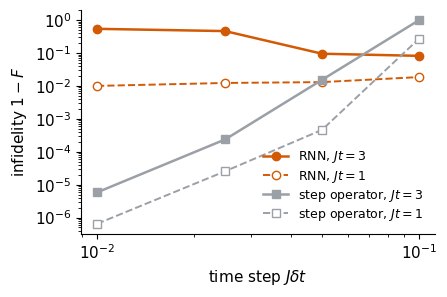

In [13]:
t_section = time.perf_counter()
@jax.jit
def heun_step_T(th, T):
    # one variational step (20) towards the normalised target T|psi_theta>, for any step matrix T
    phi = T @ amplitudes(th); phi = phi / jnp.linalg.norm(phi)
    return levenberg_marquardt(th, phi, LM_ITERS_Q)

def step_matrix(dt):
    # equation (19) with the shifted Hamiltonian
    return np.eye(2 ** N_Q) - 1j * dt * H_SHIFT - 0.5 * dt ** 2 * H_SHIFT @ H_SHIFT

def floor_curve(T, dt, n):
    # step-operator reference: T applied to the exact vector, renormalised after every step
    psi = PSI0_Q.astype(complex); inf = []
    for k in range(n + 1):
        inf.append(1 - abs(np.vdot(psi, exact_state(k * dt))) ** 2)
        psi = T @ psi; psi = psi / np.linalg.norm(psi)
    return np.array(inf)

def evolve(dt):
    # the evolution of the main run with another time step; infidelity with the exact state after every step and all D
    T = step_matrix(dt); T_j = jnp.array(T); n = int(round(T_END / dt))
    th = TH_GS; inf, D = [1 - abs(np.vdot(np.array(amplitudes(th)), exact_state(0.0))) ** 2], []
    for k in range(1, n + 1):
        th, d = heun_step_T(th, T_j); D.append(float(d))
        inf.append(1 - abs(np.vdot(np.array(amplitudes(th)), exact_state(k * dt))) ** 2)
    return np.array(inf), np.array(D), floor_curve(T, dt, n)

SCAN = {DT_Q: (INF_Q, D_STEP, INF_STEP_Q)}                    # the main run
for dt in (0.01, 0.025, 0.1):
    t0 = time.perf_counter(); SCAN[dt] = evolve(dt)
    print(f"dt = {dt:5.3f}/J: {int(round(T_END / dt)):3d} steps in {time.perf_counter() - t0:4.0f} s")
DT_SCAN = np.array(sorted(SCAN))
def at(arr, dt, t):
    return arr[int(round(t / dt))]
SCAN_TABLE = {dt: dict(inf1=at(SCAN[dt][0], dt, 1.0), inf3=SCAN[dt][0][-1], floor1=at(SCAN[dt][2], dt, 1.0), floor3=SCAN[dt][2][-1],
                       Dsum=SCAN[dt][1].sum(), steps=len(SCAN[dt][1])) for dt in DT_SCAN}
print("  dt J   steps   1-F(Jt=1)   1-F(Jt=3)   sum of D   floor(Jt=1)   floor(Jt=3)")
for dt in DT_SCAN:
    r = SCAN_TABLE[dt]
    print(f"  {dt:5.3f}  {r['steps']:4d}    {r['inf1']:.2e}    {r['inf3']:.2e}   {r['Dsum']:.2e}    {r['floor1']:.2e}     {r['floor3']:.2e}")
FLOOR_SLOPES = np.diff(np.log([SCAN_TABLE[dt]["floor3"] for dt in DT_SCAN])) / np.diff(np.log(DT_SCAN))
print("local slope of ln(floor at Jt = 3) against ln(dt):", ", ".join(f"{s:.1f}" for s in FLOOR_SLOPES))

# --- figure (drawing code may be skipped) ---
def draw_dt_scan(ax):
    inf3 = [SCAN_TABLE[dt]["inf3"] for dt in DT_SCAN]; inf1 = [SCAN_TABLE[dt]["inf1"] for dt in DT_SCAN]
    fl3 = [SCAN_TABLE[dt]["floor3"] for dt in DT_SCAN]; fl1 = [SCAN_TABLE[dt]["floor1"] for dt in DT_SCAN]
    ax.loglog(DT_SCAN, inf3, "-o", color=COL["rnn"], ms=6, lw=1.8, label="RNN, $Jt=3$")
    ax.loglog(DT_SCAN, inf1, "--o", color=COL["rnn"], ms=6, lw=1.4, mfc="white", label="RNN, $Jt=1$")
    ax.loglog(DT_SCAN, fl3, "-s", color=COL["grey"], ms=6, lw=1.8, label="step operator, $Jt=3$")
    ax.loglog(DT_SCAN, fl1, "--s", color=COL["grey"], ms=6, lw=1.4, mfc="white", label="step operator, $Jt=1$")
    ax.set_xlabel(r"time step $J\delta t$"); ax.set_ylabel("infidelity $1-F$")
    ax.legend(frameon=False, fontsize=9, loc="lower right", labelspacing=0.25)
one_panel("fig_lab089_dt_scan", draw_dt_scan)
TIMES["9 time-step scan"] = time.perf_counter() - t_section
TIMES["9 time evolution"] = TIMES["9 time evolution, main run"] + TIMES["9 time-step scan"]

The figure shows the infidelity at $Jt=3$ (filled symbols) and at $Jt=1$ (open symbols) against $\delta t$ on logarithmic axes, for the network (orange) and for the step-operator reference (grey), each from a single run. The infidelity of the reference decreases rapidly as the step shrinks. Between the two smallest steps its infidelity at $Jt=3$ grows as $\delta t^{4.0}$, as expected when each step adds an amplitude error of order $\delta t^3$ and the errors of the $3/(J\delta t)$ steps add up to order $\delta t^2$. At larger steps it grows faster, about as $\delta t^{6}$, because the eigenstates far above $\bar{\mathcal E}$ are amplified by $1+(\delta t\,\mathcal E_n)^4/4$ at every step, and at $\delta t=0.1/J$ the reference loses the exact state altogether.

At $Jt=1$ the infidelity of the network changes little with $\delta t$ and is lowest for the smallest step. At $Jt=3$ it falls as the step grows over the whole scan, although the truncation error of $\hat T$ grows by more than three orders of magnitude between $\delta t=0.01/J$ and $0.05/J$. The sum of the residuals does not explain this trend. It is $7.0\times10^{-2}$ for 300 steps and $5.7\times10^{-2}$ for 60, nearly the same, whereas the infidelities at $Jt=3$ are $0.55$ and $0.096$. The infidelity of the run with 300 steps is eight times its sum of residuals, so the deviations of successive steps build up far beyond that sum, as the angles of the main run explained. The numbers of the main run, $\delta t=0.05/J$, are reproduced bit for bit when the notebook is run again sequentially. The late-time values of the scan at the small steps are sensitive to round-off, which changes with the scheduling of parallel threads, because after $Jt\approx1$ small deviations grow from step to step, and the trend with $\delta t$ is the same in repeated runs. At $\delta t=0.1/J$ the network stays close to the exact state while the reference does not. The minimisation of $D$ returns at every step to a network state, whereas the reference applies $\hat T$ to all 256 amplitudes, so the reference measures the quality of $\hat T$ on the full space, and the error of the network can lie below it. In this calculation the best step for late times lies at the large end of the scan. Reference [5], with snapshots on a $4\times4$ lattice and a gated network, found its optimum at $g\,\delta t\approx0.01$. The main run uses $\delta t=0.05/J$, at which the truncation error of $\hat T$ stays well below the error of the network at $Jt=3$.

| single runs, $N=8$, 10 Levenberg–Marquardt iterations per step | $\delta t=0.01/J$ | $0.025/J$ | $0.05/J$ (main run) | $0.1/J$ |
|---|---|---|---|---|
| steps up to $Jt=3$ | 300 | 120 | 60 | 30 |
| RNN, $1-F$ at $Jt=1$ | $1.0\times10^{-2}$ | $1.2\times10^{-2}$ | $1.3\times10^{-2}$ | $1.9\times10^{-2}$ |
| RNN, $1-F$ at $Jt=3$ | $0.55$ | $0.47$ | $9.6\times10^{-2}$ | $8.2\times10^{-2}$ |
| sum of $D$ | $7.0\times10^{-2}$ | $0.12$ | $5.7\times10^{-2}$ | $0.13$ |
| step operator, $1-F$ at $Jt=1$ | $6.5\times10^{-7}$ | $2.6\times10^{-5}$ | $4.6\times10^{-4}$ | $0.27$ |
| step operator, $1-F$ at $Jt=3$ | $5.8\times10^{-6}$ | $2.4\times10^{-4}$ | $1.5\times10^{-2}$ | $1.0$ |

## 10. Summary

A recurrent network writes the probability of a spin configuration as a product of conditional probabilities, one for each site. The same cell computes all of them from the previous spin and a hidden vector that carries the memory of the spins before it, and a softmax makes each conditional probability normalised. The product is therefore normalised for any parameters, and for a positive state the amplitude is the product of the square roots of the conditional probabilities. The two-spin ground state at $g=J$ needs a single hidden unit, which stores the first spin and makes the second prefer the same orientation.

The product rule also draws the snapshots, one spin after the other with one random number per site, so that no two snapshots share anything. Metropolis chains on an RBM that describes nearly the same state keep a memory of several sweeps, whereas the snapshots of the recurrent network are uncorrelated.

Trained on snapshots, the recurrent network minimises the negative log-likelihood without any partition function, while the gradient of the RBM needs an average over the model distribution. Trained on the energy, it uses its own independent snapshots for the local energies and the gradient of Lab 088, in which the average of the logarithmic derivatives vanishes because the network is normalised. A projection of the conditional probabilities with Heaviside functions builds the conservation of the number of spins up into the network, and on the XY chain it removed the long first phase of training in which the plain network learns this rule from the data.

The time evolution needs a phase for every conditional probability. The matrix $S$ of the recurrent network has only a few large eigenvalues, and Ref. [5] found that the velocity equation of Lab 088 becomes unstable when this matrix is estimated from snapshots and inverted. The step of Ref. [5] replaces the velocity equation by the maximisation of an overlap with the state propagated over a short time, which with snapshots is lowered by Adam without inverting any matrix. With exact sums we fitted each step by the Levenberg–Marquardt method, whose matrix is $S$ with a diagonal shift. On eight spins this step followed the rise of the transverse magnetisation. The deviations of the individual steps then built up, and the final infidelity was larger than that of the RBM of Lab 088, which used the velocity equation with exact sums and fourth-order Runge–Kutta steps. In a scan of the time step with single runs, the late-time error grew with the number of steps, beyond the sum of the residuals, while the truncation error of the step operator shrank, and in this calculation the late times came out best for the larger steps.

## 11. Exercises

The exercises carry the same numbers as in the lecture notes.

1. Draw the probability tree of the three-spin ground state at $g=J$ from exact diagonalisation and compute $p(s_2|s_0s_1)$ for all four histories. Explain why $p(s_2=0|01)$ differs from $p(s_2=0|11)$.
2. Evaluate the network of Section 3 on all eight configurations of three spins, check that the probabilities add up to one, and draw one snapshot with equation (8) and random numbers of your choice.
3. Read the sites in a fixed random order, a random permutation of $0,\dots,N-1$, and repeat the training of Section 5. The product rule (3) holds for any order, whereas neighbouring spins of the chain now lie far apart in the reading order, so the memory has to carry their correlation over many sites. Compare the infidelity with that of the natural order after the same number of epochs, and train both orders with two further seeds to see the scatter of single runs. The reversed order $N-1,\dots,0$ gives the same task as the natural one, because the open chain is symmetric under reflection.
4. Train the recurrent network of Section 5 with 2000 and with 200 000 snapshots and compare the final infidelity with the infidelity of the square roots of the frequencies. Explain which of the two decreases faster with the number of snapshots.
5. Repeat Section 6 at $g=0.5J$, where the ground state is close to the superposition of the two ordered configurations, and compare $\tau_{\rm int}$ of the Metropolis chains with the value at $g=J$.
6. Replace the tanh cell (5) by the GRU of Lab 036 and repeat Section 7 with the same number of iterations. Compare the number of parameters and the final energy error.
7. Replace the Levenberg–Marquardt iterations of Section 9 by Adam steps on $D$, between 50 and 500 per time step as in Ref. [5], and compare the values of $D$ after each step and the infidelity at $Jt=3$. Repeat the scan of the time step with the Adam optimiser and compare where the best step lies.

## References

[1] G. Carleo and M. Troyer, Solving the quantum many-body problem with artificial neural networks, Science **355**, 602 (2017), doi:10.1126/science.aag2302.

[2] D. Wu, L. Wang and P. Zhang, Solving statistical mechanics using variational autoregressive networks, Phys. Rev. Lett. **122**, 080602 (2019), doi:10.1103/PhysRevLett.122.080602.

[3] O. Sharir, Y. Levine, N. Wies, G. Carleo and A. Shashua, Deep autoregressive models for the efficient variational simulation of many-body quantum systems, Phys. Rev. Lett. **124**, 020503 (2020), doi:10.1103/PhysRevLett.124.020503.

[4] M. Hibat-Allah, M. Ganahl, L. E. Hayward, R. G. Melko and J. Carrasquilla, Recurrent neural network wave functions, Phys. Rev. Research **2**, 023358 (2020), doi:10.1103/PhysRevResearch.2.023358.

[5] K. Donatella, Z. Denis, A. Le Boité and C. Ciuti, Dynamics with autoregressive neural quantum states: application to critical quench dynamics, Phys. Rev. A **108**, 022210 (2023), doi:10.1103/PhysRevA.108.022210.

[6] D. P. Kingma and J. Ba, Adam: a method for stochastic optimization, arXiv:1412.6980 (2014), https://arxiv.org/abs/1412.6980.

[7] DeepMind, Optax, gradient processing and optimisation for JAX, https://github.com/google-deepmind/optax.

[8] P. Pfeuty, The one-dimensional Ising model with a transverse field, Ann. Phys. **57**, 79 (1970), doi:10.1016/0003-4916(70)90270-8.

[9] K. Cho, B. van Merriënboer, C. Gulcehre, D. Bahdanau, F. Bougares, H. Schwenk and Y. Bengio, Learning phrase representations using RNN encoder–decoder for statistical machine translation, Proceedings of EMNLP 2014, 1724 (2014), doi:10.3115/v1/D14-1179.

[10] G. Torlai, G. Mazzola, J. Carrasquilla, M. Troyer, R. Melko and G. Carleo, Neural-network quantum state tomography, Nat. Phys. **14**, 447 (2018), doi:10.1038/s41567-018-0048-5.

[11] J. Carrasquilla, G. Torlai, R. G. Melko and L. Aolita, Reconstructing quantum states with generative models, Nat. Mach. Intell. **1**, 155 (2019), doi:10.1038/s42256-019-0028-1.

[12] N. Metropolis, A. W. Rosenbluth, M. N. Rosenbluth, A. H. Teller and E. Teller, Equation of state calculations by fast computing machines, J. Chem. Phys. **21**, 1087 (1953), doi:10.1063/1.1699114.

[13] E. Lieb, T. Schultz and D. Mattis, Two soluble models of an antiferromagnetic chain, Ann. Phys. **16**, 407 (1961), doi:10.1016/0003-4916(61)90115-4.

[14] S. Morawetz, I. J. S. De Vlugt, J. Carrasquilla and R. G. Melko, U(1)-symmetric recurrent neural networks for quantum state reconstruction, Phys. Rev. A **104**, 012401 (2021), doi:10.1103/PhysRevA.104.012401.

[15] K. Levenberg, A method for the solution of certain non-linear problems in least squares, Q. Appl. Math. **2**, 164 (1944), doi:10.1090/qam/10666.

[16] D. W. Marquardt, An algorithm for least-squares estimation of nonlinear parameters, J. Soc. Ind. Appl. Math. **11**, 431 (1963), doi:10.1137/0111030.

The last cell prints the runtimes of all sections. When `SAVE_RESULTS` is `True`, it also saves every figure, writes every number quoted in the text to a file of LaTeX macros and writes the results file.

In [14]:
# Bookkeeping: runtimes; files only if SAVE_RESULTS is True.
TOTAL_SECONDS = time.perf_counter() - started
for k, v in TIMES.items():
    print(f"section {k}: {v:.1f} s")
print(f"core route {CORE_SECONDS:.0f} s, total {TOTAL_SECONDS:.0f} s")
NUMBERS.update(
    TomoRnnInf=sci(HIST_RNN[-1, 0]), TomoRnnDE=sci(HIST_RNN[-1, 1]), TomoRbmInf=sci(HIST_RBM[-1, 0]), TomoRbmDE=sci(HIST_RBM[-1, 1]),
    TomoRnnInfOne=sci(HIST_RNN[1, 0]), TomoRbmInfOne=sci(HIST_RBM[1, 0]), HistDE=sci(HIST_DE), GradCheckRbm=sci(grad_check_rbm, 0),
    TomoRnnSeconds=f"{SEC_RNN_T:.0f}", TomoRbmSeconds=f"{SEC_RBM_T:.0f}",
    ChainAccept=f"{ACCEPT:.2f}", TauIntChain=f"{TAU_INT_CHAIN:.1f}", TauIntRnn=f"{TAU_INT_RNN:.2f}", CChainOne=f"{C_CHAIN[1]:.2f}",
    CChainTen=f"{C_CHAIN[10]:.2f}", CRnnOneAbs=sci(abs(C_RNN[1])), MsqChain=f"{np.mean(M_CHAIN ** 2):.3f}", MsqRnn=f"{np.mean(M_RNN ** 2):.3f}",
    MsqExact=f"{PSI0_T ** 2 @ M_OF ** 2:.3f}",
    EnergyEzero=f"{E0_E:.4f}", EnergyRelErr=sci(REL_E[-1]), EnergyInf=sci(EXACT_LOG[-1, 2]), EnergyFinal=f"{EXACT_LOG[-1, 1]:.4f}",
    EnergyVar=sci(VAR_EST[-50:].mean()), EnergySeconds=f"{SEC_E:.0f}", EnergyIters=str(ITERS), EnergySnaps=str(N_S),
    LabEightyRelErr=sci(LAB080["rel_err"]), LabEightyFid=f"{LAB080['fidelity']:.5f}", GradCheckE=sci(grad_check_E, 0),
    XYEzero=f"{E0_XY:.4f}", XYPlainInfOne=sci(HIST_PLAIN[1, 0]), XYPlainInf=sci(HIST_PLAIN[-1, 0]), XYUoneInfOne=sci(HIST_U1[1, 0]),
    XYUoneInf=sci(HIST_U1[-1, 0]), XYOutOne=f"{HIST_PLAIN[1, 3]:.2f}", XYOutLast=f"{HIST_PLAIN[-1, 3]:.3f}",
    XYPlainDE=sci(HIST_PLAIN[-1, 1]), XYUoneDE=sci(HIST_U1[-1, 1]),
    QGsInf=sci(float(D_GS)), QRnnParams=str(len(TH_START)), QRnnAbove=str(int(np.sum(LAM_RNN > 1e-3 * LAM_RNN[0]))),
    QRbmAbove=str(int(np.sum(LAM_RBM > 1e-3 * LAM_RBM[0]))), QRnnAboveSix=str(int(np.sum(LAM_RNN > 1e-6 * LAM_RNN[0]))),
    QRbmAboveSix=str(int(np.sum(LAM_RBM > 1e-6 * LAM_RBM[0]))), QDt=f"{DT_Q}", QEbar=f"{E_BAR:.4f}", QIters=str(LM_ITERS_Q),
    QDxMax=f"{DX_MAX:.3f}", QInfT=sci(INF_Q[-1]), QDMedian=sci(np.median(D_STEP)), QDMax=sci(np.max(D_STEP)), QDSum=sci(D_STEP.sum()),
    QSeconds=f"{SEC_TE:.0f}", QDirectOne=sci(DIRECT[1.0]), QDirectThree=sci(DIRECT[3.0]), QInfOne=sci(INF_Q[int(round(1.0 / DT_Q))]), QInfHalf=sci(INF_Q[int(round(0.5 / DT_Q))]), LabEightyEightDx=f"{LAB088['max_abs_dx']:.3f}", LabEightyEightInfT=sci(LAB088["infid_T"]), LabEightyEightDt=f"{LAB088['dt']}",
    QSteps=str(n_steps), QEspread=f"{E_SPREAD:.1f}", QStepFloor=sci(INF_STEP_Q[-1]), QStepFloorOne=sci(INF_STEP_Q[int(round(1.0 / DT_Q))]),
    QStepFloorUnshift=sci(INF_STEP_UNSHIFT[-1]), QStepDxMax=sci(DX_STEP_MAX),
    **{f"QScan{q}Dt{name}": sci(SCAN_TABLE[dt][key]) for dt, name in ((0.01, "One"), (0.025, "TwoFive"), (0.05, "Five"), (0.1, "Ten"))
       for q, key in (("InfT", "inf3"), ("InfOne", "inf1"), ("FloorT", "floor3"), ("FloorOne", "floor1"), ("DSum", "Dsum"))},
    QScanFloorSlopeSmall=f"{FLOOR_SLOPES[0]:.1f}", QScanFloorSlopeLarge=f"{FLOOR_SLOPES[-1]:.1f}",
    QScanSeconds=f"{TIMES['9 time-step scan']:.0f}", QMainSeconds=f"{TIMES['9 time evolution, main run']:.0f}",
    CoreSeconds=f"{CORE_SECONDS:.0f}", TotalSeconds=f"{TOTAL_SECONDS:.0f}",
    XYSeconds=f"{TIMES['8 conservation law']:.0f}", TESeconds=f"{TIMES['9 time evolution']:.0f}")
if SAVE_RESULTS:
    FIG, RES = Path("figures"), Path("classroom_results"); FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
    SLIDE_RC = {"font.size": 12.5, "axes.labelsize": 12.5, "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12}
    def save(fig, name):
        fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=150); plt.close(fig)
    def single(draw, name):                              # one panel at 4.6 x 3.1 in with 12.5 pt fonts (slides)
        with plt.rc_context(SLIDE_RC):
            fig, ax = plt.subplots(figsize=(4.6, 3.1)); draw(ax); fig.tight_layout(); save(fig, name)
    for name, draws in FIGURES:                          # notes: panels side by side at 7.0 x 2.9 in; slides: every panel alone
        if len(draws) == 1:
            single(draws[0], name); continue
        fig, axes = plt.subplots(1, len(draws), figsize=(7.0, 2.9))
        for ax, draw, lab in zip(axes, draws, "abcdef"):
            draw(ax); ax.set_title(f"({lab})", loc="left", fontsize=11)
        fig.tight_layout(); save(fig, name)
        for draw, lab in zip(draws, "abcdef"):
            single(draw, f"{name}_{lab}")
    with open(FIG / "nb_numbers_lab089.tex", "w") as f:
        f.write("% numbers quoted in the text, written by Lab_089_Recurrent_neural_network_quantum_state.ipynb (Lecture 17)\n")
        for k, v in NUMBERS.items():
            f.write(f"\\providecommand{{\\labeightynine{k}}}{{{v}}}\n")
    results = dict(
        experiment="Recurrent neural network quantum state (tanh cell, softmax conditionals) for the open transverse-field Ising chain: "
                   "two-spin product rule, exact site-by-site sampling, tomography from z snapshots (N = 10) against an exact-sum RBM, "
                   "Metropolis autocorrelation, energy minimisation with exact RNN snapshots (N = 12), U(1) projection on the XY chain (N = 10), "
                   "variational Heun step with exact sums (N = 8 quench g = 0.5 J -> J); JAX float64 on CPU",
        two_spins=dict(r=float(r_two), p=p2.tolist(), p_s0=p_s0.tolist(), p_cond=p_cond.tolist(), one_unit_v=float(v_two)),
        tiny_network=dict(psi_011=float(TINY_PSI011), sampled_snapshot=TABLE_SNAPSHOT),
        normalisation_random_N10=float(norm_dev),
        tomography=dict(N=N_T, g=G_T, E0=E0_T, snapshots=N_DATA, distinct=int(np.count_nonzero(freq_T)), epochs=EPOCHS, batch=BATCH,
                        step_size="cosine 1e-2 -> 1e-4", rnn_params=n_params(RNN_T), rbm_params=n_params(RBM_T), rbm_M=M_T,
                        rnn_history=HIST_RNN.tolist(), rbm_history=HIST_RBM.tolist(), frequencies=[float(HIST_INF), float(HIST_DE)],
                        rbm_gradient_check=grad_check_rbm, seconds=dict(rnn=SEC_RNN_T, rbm=SEC_RBM_T), runs=1),
        autocorrelation=dict(chains=CHAINS, burn_in=BURN, recorded=RECORD, acceptance=float(ACCEPT), C_chain=C_CHAIN.tolist(),
                             C_rnn=C_RNN.tolist(), tau_int_chain=float(TAU_INT_CHAIN), tau_int_rnn=float(TAU_INT_RNN)),
        energy=dict(N=N_E, g=G_E, E0=E0_E, iterations=ITERS, snapshots=N_S, step_size="cosine 1e-2 -> 1e-4", n_h=16,
                    exact_log=EXACT_LOG.tolist(), final_rel_err=float(REL_E[-1]), final_infidelity=float(EXACT_LOG[-1, 2]),
                    gradient_check=grad_check_E, seconds=SEC_E, lab080_recorded=LAB080, runs=1),
        xy=dict(N=N_XY, E0=E0_XY, snapshots=int(len(DATA_XY)), epochs=EPOCHS_XY, batch=BATCH_XY, step_size=1e-3,
                plain_history=HIST_PLAIN.tolist(), u1_history=HIST_U1.tolist(), columns=["1-F", "dE/|E0|", "outside (snapshots)", "outside (exact)"], runs=1),
        quench=dict(N=N_Q, g_i=G_I, g_f=G_F, dt=DT_Q, lm_iterations=LM_ITERS_Q, n_h=16, params=len(TH_START), gs_infidelity=float(D_GS), gs_infidelity_starts=D_GS_STARTS,
                    t=T_Q.tolist(), X_exact=X_EXACT_Q.tolist(), X_rnn=X_RNN_Q.tolist(), infidelity=INF_Q.tolist(), D_step=D_STEP.tolist(),
                    max_abs_dx=float(DX_MAX), direct_fit_infidelity={str(k): v for k, v in DIRECT.items()}, lab088_recorded=LAB088, energy_shift=float(E_BAR), S_eigen_rnn=LAM_RNN.tolist(), S_eigen_rbm=LAM_RBM.tolist(), seconds=SEC_TE,
                    energy_spread=float(E_SPREAD), steps=n_steps,
                    step_operator_reference=dict(X=X_STEP_Q.tolist(), infidelity=INF_STEP_Q.tolist(), infidelity_unshifted=INF_STEP_UNSHIFT.tolist(),
                                                 max_abs_dx=float(DX_STEP_MAX)),
                    dt_scan={str(dt): dict(t_step=dt, infidelity=SCAN[dt][0].tolist(), D_step=SCAN[dt][1].tolist(), floor=SCAN[dt][2].tolist(),
                                            **{k: float(v) for k, v in SCAN_TABLE[dt].items()}) for dt in DT_SCAN},
                    floor_slopes=FLOOR_SLOPES.tolist()),
        seconds=dict(TIMES, core=CORE_SECONDS, total=TOTAL_SECONDS))
    (RES / "lab089_results.json").write_text(json.dumps(results, indent=1))
    print("saved", len(FIGURES), "figures, the macro file and the results file")

section 2 two spins: 0.2 s
section 3 recurrent cell: 0.8 s
section 4 sampling: 2.0 s
section 5 learning from snapshots: 13.6 s
section 6 Markov-chain and independent snapshots: 0.7 s
section 7 ground state from the energy: 28.2 s
section 8 conservation law: 27.6 s
section 9 time evolution, main run: 53.1 s
section 9 time-step scan: 206.4 s
section 9 time evolution: 259.5 s
core route 46 s, total 333 s
saved 8 figures, the macro file and the results file
